# Homework #3. Exploratory Data Analysis (EDA)
**Team ID:** 7  
**Topic:** Kartonky × Reddit: Offline vs Online Protest Discourse (July–August 2026)  
**Time spent on this assignment:** approx 7 hours

---

## 0. Abstract

In July 2026 Ukraine saw street protests after the dismissal of Defence Minister Mykhailo Fedorov. Our project compares two traces of that event: **offline** (4,448 protest posters from the Kartonky archive) and **online** (34,424 submissions and 1,467,671 comments from eight subreddits, July–August 2026). This notebook explores the Reddit side in depth and uses the posters as a reference point.

**What we found:**
1. Reddit's *total* activity does not react to the protests (Fig. 4), but the *topic* does: comments mentioning Fedorov jump from 129 on 15 July to **614 on 16 July**, with the first surge at 21:00 on 15 July (Figs. 11–12).
2. The reaction is not equal across communities: English-language Ukraine-focused subreddits mention Fedorov **432 times per 10,000 comments**, Ukrainian communities 228, international subreddits only 40 (Fig. 13).
3. The 16 July spike is made by established users, not by newcomers (Fig. 14).
4. Posters and comments overlap in vocabulary only partly: posters are slogans ("поверніть Федорова", "Сирського геть"), comments analyse the event ("defense minister", "anti-corruption") (Figs. 17–18).
5. The two data sources can be joined reliably (99% of comments find their submission, Fig. 10), and participation is highly concentrated: the top 1% of authors write 24% of all comments (Fig. 6).
6. The Ukrainian communities are not the angriest: 67% of their comments about Fedorov are negative, against 85% in the English-language and international subreddits (Fig. 19), so hypothesis H2 (sentiment divergence) is not supported.

Hypothesis H3 (news-driven secondary spikes) is deliberately left for the next stage, when the news data will be collected.

## 1. Introduction and background

### 1.1 The event

In mid-July 2026 Ukrainian President Volodymyr Zelensky dismissed Defence Minister Mykhailo Fedorov, a minister widely seen as popular. Protests against the decision spread across the country within days and continued for weeks; one outlet counted the 35th day of protests on 19 August, when parliament appointed a new defence minister ([NPR, 16 Jul](https://www.npr.org/2026/07/16/g-s1-133920/ukraine-defense-minister-fired); [Meduza, 16 Jul](https://meduza.io/amp/en/news/2026/07/16/protests-spread-across-ukraine-against-the-removal-of-defense-minister-mykhailo-fedorov); [Shelter, 20 Aug](https://shelter.in.ua/en/polityka/35-y-den-protestiv-na-pidtrymku-fedorova-aktsiyi-vidbulysia-navit-pislia-pryznachennia-khmary)). Protesters carried hand-made cardboard posters (*картонки*) with slogans, and the posters were collected in an online archive, **Kartonky**. At the same time the event was discussed online, including on Reddit.

### 1.2 Why compare offline and online?

A protest leaves two kinds of traces. Posters are *deliberate, condensed messages* written to be seen on the street: short slogans, names, demands. Online comments are *conversation*: longer, argumentative, and written by an audience that may never have attended a protest. Comparing them shows whether the street and the online public talk about the same things, in the same words, at the same time — and whether different online communities frame the event differently.

### 1.3 The data this report starts from

In the earlier homework (HW2) our team collected and cleaned three sources, which are the input of this report:

* **Kartonky posters:** 4,448 posters from the archive author's export of 21 September 2026 (text, self-reported city, date, how the text and date were obtained). Poster images are not published — only analysis of the texts, as the archive author requested.
* **Reddit submissions and comments, July–August 2026:** 34,424 submissions and 1,467,671 comments from eight subreddits in three groups (Ukrainian communities, Ukraine-focused English-language, international). The raw monthly dumps were filtered to these subreddits and the period (1.23 GB), cleaned without deleting records (removed/deleted content and bots are flagged), and stored with UTC and Kyiv-local timestamps.

## 2. Research questions and hypotheses

Our story is told from three angles: *when* things happen (temporal), *who and where* they happen (structural) and *what is said* (textual). It begins with the plainest questions about the data. Which subreddits and groups dominate it (Q1), and how much of it is unusable because it was removed, deleted or written by bots (Q2)? What do the offline posters look like, and how far can we trust them (Q3)? From there we ask whether overall Reddit activity changes when the protests start (Q4), when during the day and week the communities comment (Q5), and how concentrated participation is among authors (Q6). We then look at the shape of the discussion: how comment scores and lengths are distributed (Q7), and whether a submission's popularity predicts the size of its discussion (Q8). The two Reddit sources have to meet, so we ask whether submissions and comments can be joined and how complete the result is (Q9).

The central part of the story follows the protest itself: when the online and offline reactions peak and how quickly Reddit responds (Q10), and who reacts, where and in which threads (Q11). Finally, we turn to the words. Do posters and comments share a vocabulary (Q12), how negative is the tone in each community group (Q13), and how noisy are the OCR-extracted poster texts (Q14)? Each question is answered by a figure (Figs. 1–20), and Section 5.1 gathers the answers.

Four hypotheses guide the text analysis. **H1** expects lexical convergence in 15–20 July: comments about Fedorov should use the vocabulary of the posters. **H2** expects sentiment divergence: Ukrainian communities should be markedly more negative about Fedorov than international subreddits, which should stay neutral. **H3** expects news-driven secondary spikes on 21–22 July and 19 August; it is postponed to the news stage. **H4** expects OCR-extracted poster texts to contain systematic errors compared with typed ones.

## 3. Proposed approach

The input is the three cleaned files from HW2 (Section 1.3). All times are given in **Kyiv local time (UTC+3)**. The core window is **15–20 July 2026**, and the rest of July–August serves as the baseline. A comment counts as being about Fedorov if it matches `fedorov|федоров` (bots excluded). Because the three groups differ about thirty-fold in volume, we compare them by **rates** (per 10,000 comments) and indexed series, never by raw counts.

Each question gets the simplest measure that can answer it. Timing (Q10) is read from daily and hourly counts of Fedorov comments set against poster dates (Figs. 11–12), and intensity by community (Q11) from mentions per 10,000 comments (Fig. 13). H1 is tested with top bigrams and with the cosine similarity of TF-IDF centroids of posters and comments, after removing the word *Fedorov* itself, and is reported with bootstrap 95% intervals (Figs. 17–18). H2 is measured as the share of negative comments according to a multilingual transformer (XLM-R), with Wilson 95% intervals (Fig. 19). H4 compares `ocr` and `user` posters on four noise metrics (out-of-vocabulary rate, mixed-script words, unusual symbols and isolated letters), using a bootstrap interval for the difference (Fig. 20). H3 has no measure yet, because it waits for the news data.

## 4. Implementation

### 4.1 Setup, data loading and aggregation

The 640 MB comments file is streamed once into small aggregate tables that are cached in `reports/cache/`, so the notebook stays light. Bots are excluded from text analyses and rates, while removed and deleted comments remain in the activity counts.

In [1]:
import os, re, pickle, warnings
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from IPython.display import display
from scipy import stats

warnings.filterwarnings("ignore")

# Project root: <root>/data/clean/*.csv ; override with the EDA_ROOT environment variable if needed
ROOT = Path(os.environ["EDA_ROOT"]) if "EDA_ROOT" in os.environ else (
    Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd())
CLEAN, FIG, CACHE = ROOT / "data" / "clean", ROOT / "reports" / "figures", ROOT / "reports" / "cache"
FIG.mkdir(parents=True, exist_ok=True); CACHE.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_colwidth", 90); pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

# Subreddit groups (chosen in HW2) and the colour of each group (fixed across all figures)
GROUPS = {
    "reddit_ukr": "Ukrainian communities", "RedditUATalks": "Ukrainian communities", "Kyiv": "Ukrainian communities",
    "ukraine": "Ukraine-focused (EN)", "UkrainianConflict": "Ukraine-focused (EN)",
    "worldnews": "International", "europe": "International", "UkraineRussiaReport": "International",
}
GROUP_ORDER = ["Ukrainian communities", "Ukraine-focused (EN)", "International"]
SUB_ORDER = list(GROUPS)                                       # already ordered by group
SERIES = {"Ukrainian communities": "#2a78d6", "Ukraine-focused (EN)": "#eb6834", "International": "#1baf7a"}
SURFACE, INK, INK_2, GRID, ACCENT = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e1", "#2a78d6"
PROTEST_START = pd.Timestamp("2026-07-16")
DAYS = pd.date_range("2026-07-01", "2026-08-31")               # 1 Sep (Kyiv) holds only 3 hours of data -> excluded from daily plots

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.linewidth": 1, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 1,
    "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
    "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2, "text.color": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 9.5, "lines.linewidth": 1.8, "figure.dpi": 100, "legend.frameon": False,
})
thousands = plt.FuncFormatter(lambda x, _: f"{x:,.0f}")

def group_legend(ax, loc="best", **kw):
    ax.legend(handles=[Patch(color=SERIES[g], label=g) for g in GROUP_ORDER], loc=loc, **kw)

def finish(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight"); plt.show()

In [2]:
import pickle
import re
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd

GROUPS = {
    "reddit_ukr": "Ukrainian communities", "RedditUATalks": "Ukrainian communities", "Kyiv": "Ukrainian communities",
    "ukraine": "Ukraine-focused (EN)", "UkrainianConflict": "Ukraine-focused (EN)",
    "worldnews": "International", "europe": "International", "UkraineRussiaReport": "International",
}
FEDOROV = r"fedorov|федоров"
KEYWORDS = {
    "Fedorov": FEDOROV,
    "Syrskyi": r"syrsk|сирськ",
    "Zelensky": r"zelensk|зеленськ",
    "protest": r"protest|протест|мітинг",
    "prisoners": r"prisoner|полонен",
    "election": r"election|вибор",
}
WINDOW = ("2026-07-15", "2026-07-20")
HOURLY = ("2026-07-14", "2026-07-19")
CYR = re.compile(r"[Ѐ-ӿ]")
LAT = re.compile(r"[A-Za-z]")
USECOLS = ["id", "link_id", "subreddit", "author", "score", "controversiality", "body", "datetime_local",
           "date_local", "text_removed", "is_top_level", "author_deleted", "is_automod"]


def aggregate_comments(path, chunksize=200_000, seed=7):
    rng = np.random.default_rng(seed)
    day_sub, hour_tab, fed_hourly, kw_day = [], [], [], []
    authors, author_first, author_groups = Counter(), {}, set()
    score_hist = {g: Counter() for g in set(GROUPS.values())}
    len_hist = {g: Counter() for g in set(GROUPS.values())}
    threads = Counter()
    fed_rows, base_rows = [], []
    n_rows = 0

    for ch in pd.read_csv(path, usecols=USECOLS, dtype=str, keep_default_na=False, chunksize=chunksize):
        n_rows += len(ch)
        ch["group"] = ch["subreddit"].map(GROUPS)
        ch["human"] = ch["is_automod"] != "True"
        ch["removed"] = ch["text_removed"] == "True"
        ch["top"] = ch["is_top_level"] == "True"
        ch["score_i"] = pd.to_numeric(ch["score"], errors="coerce").fillna(0).astype(int)
        ch["adel"] = ch["author_deleted"] == "True"
        ch["contro"] = pd.to_numeric(ch["controversiality"], errors="coerce").fillna(0).astype(int)
        low = ch["body"].str.lower()
        ch["fed"] = ch["human"] & low.str.contains(FEDOROV, regex=True)
        n_cyr, n_lat = low.str.count(CYR), low.str.count(LAT)
        ch["cyr"] = (n_cyr > n_lat) & (n_cyr > 0)
        ch["hour"] = ch["datetime_local"].str[11:13].astype(int)
        ch["weekday"] = pd.to_datetime(ch["date_local"]).dt.weekday
        ch["words"] = low.str.count(r"\S+")

        day_sub.append(ch.groupby(["date_local", "subreddit"]).agg(
            n=("id", "size"), human=("human", "sum"), removed=("removed", "sum"), top=("top", "sum"),
            adel=("adel", "sum"), fed=("fed", "sum"), cyr=("cyr", "sum"), score_sum=("score_i", "sum"), contro=("contro", "sum")))
        hum = ch[ch["human"]]
        hour_tab.append(hum.groupby(["group", "weekday", "hour"]).size().rename("n"))

        hf = ch[ch["fed"] & (ch["date_local"] >= HOURLY[0]) & (ch["date_local"] <= HOURLY[1])]
        fed_hourly.append(hf.assign(h=hf["datetime_local"].str[:13]).groupby(["h", "group"]).size().rename("n"))

        kd = {}
        for name, rx in KEYWORDS.items():
            kd[name] = (ch["human"] & low.str.contains(rx, regex=True)).groupby(
                [ch["date_local"], ch["group"]]).sum()
        kw_day.append(pd.DataFrame(kd))

        # authors (real, non-bot)
        real = hum[hum["author_deleted"] != "True"]
        authors.update(real["author"])
        fmin = real.groupby("author")["date_local"].min()
        for a, d in fmin.items():
            if a not in author_first or d < author_first[a]:
                author_first[a] = d
        author_groups.update(map(tuple, real[["author", "group"]].drop_duplicates().to_numpy()))

        for g, sub in hum.groupby("group"):
            score_hist[g].update(sub["score_i"].clip(-50, 5000))
            len_hist[g].update((sub["words"].clip(upper=300) // 5) * 5)
        threads.update(hum["link_id"])

        keep = ["id", "link_id", "subreddit", "group", "author", "score_i", "datetime_local", "date_local", "top", "body"]
        fed_rows.append(ch.loc[ch["fed"], keep].assign(body=lambda d: d["body"].str[:1200]))
        w = ch[ch["human"] & ~ch["fed"] & (ch["date_local"] >= WINDOW[0]) & (ch["date_local"] <= WINDOW[1])
               & ~ch["removed"]]
        w = w[rng.random(len(w)) < 0.15]
        base_rows.append(w[keep].assign(body=lambda d: d["body"].str[:600]))

    cat = lambda parts: pd.concat(parts)
    out = {
        "n_rows": n_rows,
        "day_sub": cat(day_sub).groupby(level=[0, 1]).sum(),
        "hour_tab": cat(hour_tab).groupby(level=[0, 1, 2]).sum(),
        "fed_hourly": cat(fed_hourly).groupby(level=[0, 1]).sum(),
        "kw_day": cat(kw_day).groupby(level=[0, 1]).sum(),
        "authors": authors, "author_first": author_first, "author_groups": author_groups,
        "score_hist": score_hist, "len_hist": len_hist, "threads": threads,
        "fed_comments": cat(fed_rows).reset_index(drop=True),
        "baseline_window": cat(base_rows).reset_index(drop=True),
    }
    return out


def load_or_build(path, cache_file):
    cache_file = Path(cache_file)
    if cache_file.exists():
        with open(cache_file, "rb") as f:
            return pickle.load(f)
    agg = aggregate_comments(path)
    cache_file.parent.mkdir(parents=True, exist_ok=True)
    with open(cache_file, "wb") as f:
        pickle.dump(agg, f)
    return agg

In [3]:
# ---- load the three clean files; comments are aggregated in ONE streaming pass (640 MB) and cached ----
kart = pd.read_csv(CLEAN / "kartonky_clean.csv", dtype={"text_source": str})
subs = pd.read_csv(CLEAN / "reddit_submissions.csv", dtype=str, keep_default_na=False)
subs["group"] = subs["subreddit"].map(GROUPS)
for c in ["score", "num_comments"]:
    subs[c] = pd.to_numeric(subs[c], errors="coerce").fillna(0).astype(int)
subs["date"] = pd.to_datetime(subs["date_local"])

agg = load_or_build(CLEAN / "reddit_comments.csv", CACHE / "comments_agg.pkl")   # first run ~2-4 min, then instant
ds = agg["day_sub"].reset_index()
ds["group"] = ds["subreddit"].map(GROUPS); ds["date"] = pd.to_datetime(ds["date_local"])

print(f"Kartonky posters: {len(kart):,} | Reddit submissions: {len(subs):,} | Reddit comments: {agg['n_rows']:,}")
print(f"Unique (non-bot, non-deleted) comment authors: {len(agg['authors']):,} | threads with >=1 comment: {len(agg['threads']):,}")

Kartonky posters: 4,448 | Reddit submissions: 34,424 | Reddit comments: 1,467,671
Unique (non-bot, non-deleted) comment authors: 236,430 | threads with >=1 comment: 26,035


### 4.2 Dataset overview

#### 4.2.1 Size and timeframe

The story covers 1 July – 31 August 2026 in Kyiv time. The last day, 1 September, holds only three hours of data (44 submissions and 2,841 comments) and is left out of the daily plots.

In [4]:
by_month = pd.DataFrame({
    "submissions": subs.groupby(subs["date_local"].str[:7]).size(),
    "comments": ds.groupby(ds["date_local"].str[:7])["n"].sum(),
}).fillna(0).astype(int)
by_month["comments per submission"] = (by_month["comments"] / by_month["submissions"]).round(1)
by_month.loc["total"] = [by_month["submissions"].sum(), by_month["comments"].sum(),
                         round(by_month["comments"].sum() / by_month["submissions"].sum(), 1)]
by_month.index.name = "month (Kyiv time)"
display(by_month.assign(submissions=by_month["submissions"].map("{:,.0f}".format), comments=by_month["comments"].map("{:,.0f}".format)))

,submissions,comments,comments per submission
month (Kyiv time),,,
2026-07,"18,684","761,889",40.8
2026-08,"15,696","702,941",44.8
2026-09,44,"2,841",64.6
total,"34,424","1,467,671",42.6


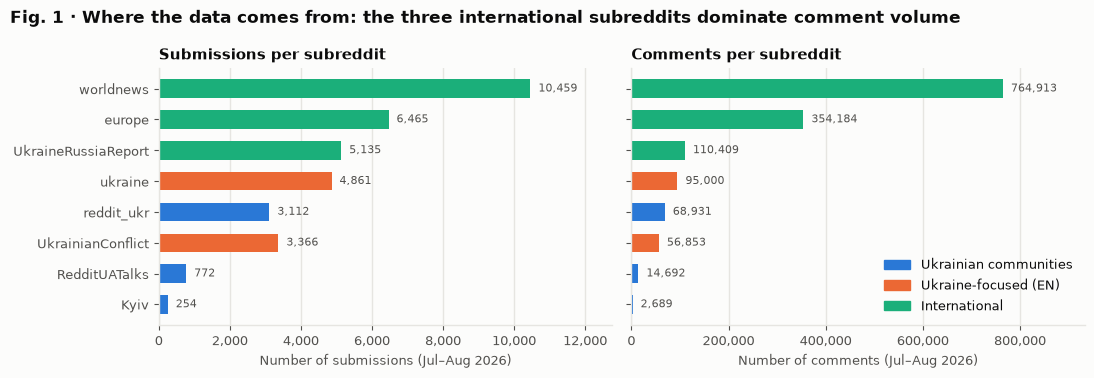

In [5]:
# Fig. 1 - volume per subreddit
sub_cnt = subs["subreddit"].value_counts()
com_cnt = ds.groupby("subreddit")["n"].sum()
order = com_cnt.sort_values().index
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, s, ttl in zip(axes, [sub_cnt, com_cnt], ["Submissions", "Comments"]):
    v = s.reindex(order)
    ax.barh(order, v.values, color=[SERIES[GROUPS[x]] for x in order], height=0.6)
    for y, val in enumerate(v.values):
        ax.text(val, y, f"  {val:,}", va="center", fontsize=8, color=INK_2)
    ax.set_title(f"{ttl} per subreddit"); ax.set_xlabel(f"Number of {ttl.lower()} (Jul–Aug 2026)")
    ax.set_xlim(0, v.max() * 1.22); ax.xaxis.set_major_formatter(thousands); ax.grid(axis="y", visible=False)
group_legend(axes[1], loc="lower right")
fig.suptitle("Fig. 1 · Where the data comes from: the three international subreddits dominate comment volume", x=0.01, ha="left", fontsize=12, weight="bold")
fig.tight_layout(); finish(fig, "fig01_volume_per_subreddit")

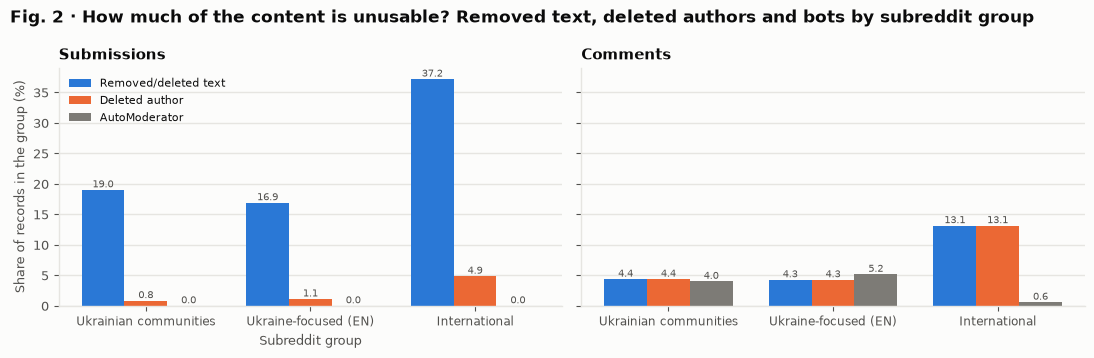

group,Ukrainian communities,Ukraine-focused (EN),International
Removed/deleted text,4.4,4.3,13.1
Deleted author,4.4,4.3,13.1
AutoModerator,4.0,5.2,0.6


In [6]:
# Fig. 2 - share of removed / deleted / bot content per group
g = ds.groupby("group")[["n", "human", "removed", "adel"]].sum().reindex(GROUP_ORDER)
cm = pd.DataFrame({"Removed/deleted text": g["removed"] / g["n"], "Deleted author": g["adel"] / g["n"],
                   "AutoModerator": (g["n"] - g["human"]) / g["n"]}) * 100
sg = subs.groupby("group")
sm = pd.DataFrame({"Removed/deleted text": sg["text_removed"].apply(lambda s: (s == "True").mean()),
                   "Deleted author": sg["author_deleted"].apply(lambda s: (s == "True").mean()),
                   "AutoModerator": sg["is_automod"].apply(lambda s: (s == "True").mean())}).reindex(GROUP_ORDER) * 100
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
cols = ["#2a78d6", "#eb6834", "#7d7b76"]
for ax, df_, ttl in zip(axes, [sm, cm], ["Submissions", "Comments"]):
    x = np.arange(len(df_)); w = 0.26
    for i, c in enumerate(df_.columns):
        ax.bar(x + (i - 1) * w, df_[c], width=w, color=cols[i], label=c)
        for xi, v in zip(x + (i - 1) * w, df_[c]):
            ax.text(xi, v + 0.4, f"{v:.1f}", ha="center", fontsize=7.5, color=INK_2)
    ax.set_xticks(x); ax.set_xticklabels(df_.index, fontsize=8.5); ax.set_title(ttl); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Share of records in the group (%)"); axes[0].set_xlabel("Subreddit group"); axes[0].legend(loc="upper left", fontsize=8)
fig.suptitle("Fig. 2 · How much of the content is unusable? Removed text, deleted authors and bots by subreddit group", x=0.01, ha="left", fontsize=12, weight="bold")
fig.tight_layout(); finish(fig, "fig02_flagged_content")
display(cm.round(1).T)

Figures 1 and 2 show why rates are needed: the three international subreddits hold 84% of all comments, so raw counts would drown the Ukrainian voices. They also show that in comments, removed text and deleted authors largely coincide.

#### 4.2.2 The offline side: Kartonky posters

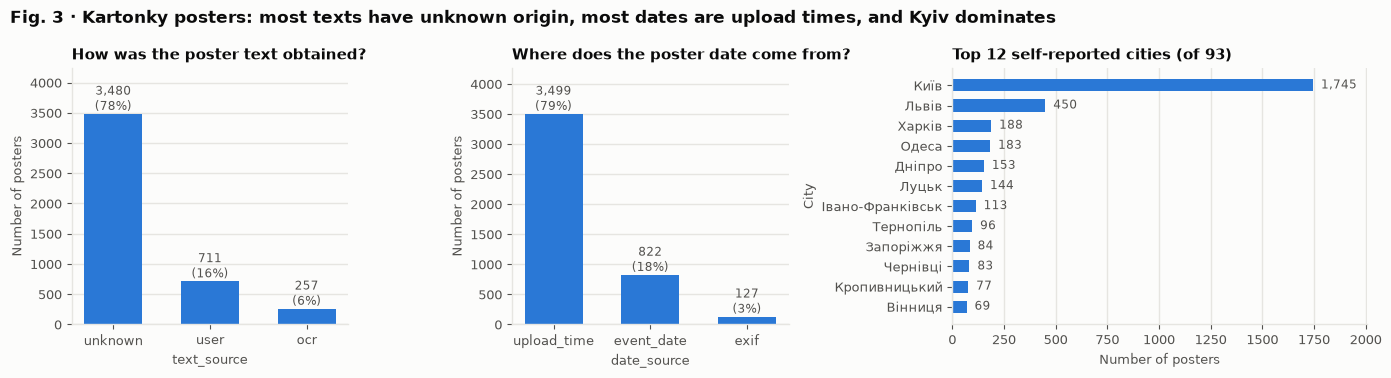

In [7]:
# Fig. 3 - Kartonky: how reliable is each poster's text and date, and where do posters come from
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), gridspec_kw={"width_ratios": [1, 1, 1.5]})
for ax, col, ttl, lab in [(axes[0], "text_source", "How was the poster text obtained?", "text_source"),
                          (axes[1], "date_source", "Where does the poster date come from?", "date_source")]:
    vc = kart[col].fillna("missing").value_counts()
    ax.bar(vc.index, vc.values, color=ACCENT, width=0.6)
    for i, v in enumerate(vc.values):
        ax.text(i, v, f"{v:,}\n({v/len(kart):.0%})", ha="center", va="bottom", fontsize=8.5, color=INK_2)
    ax.set_title(ttl); ax.set_xlabel(lab); ax.set_ylabel("Number of posters"); ax.set_ylim(0, vc.max() * 1.22); ax.grid(axis="x", visible=False)
cities = kart["city_norm"].value_counts().head(12).sort_values()
axes[2].barh(cities.index, cities.values, color=ACCENT, height=0.6)
for y, v in enumerate(cities.values):
    axes[2].text(v, y, f"  {v:,}", va="center", fontsize=8.5, color=INK_2)
axes[2].set_title(f"Top 12 self-reported cities (of {kart['city_norm'].nunique()})"); axes[2].set_xlabel("Number of posters"); axes[2].set_ylabel("City")
axes[2].set_xlim(0, cities.max() * 1.15); axes[2].grid(axis="y", visible=False)
fig.suptitle("Fig. 3 · Kartonky posters: most texts have unknown origin, most dates are upload times, and Kyiv dominates", x=0.01, ha="left", fontsize=12, weight="bold")
fig.tight_layout(); finish(fig, "fig03_kartonky_overview")

### 4.3 Activity and distributions

#### 4.3.1 Time

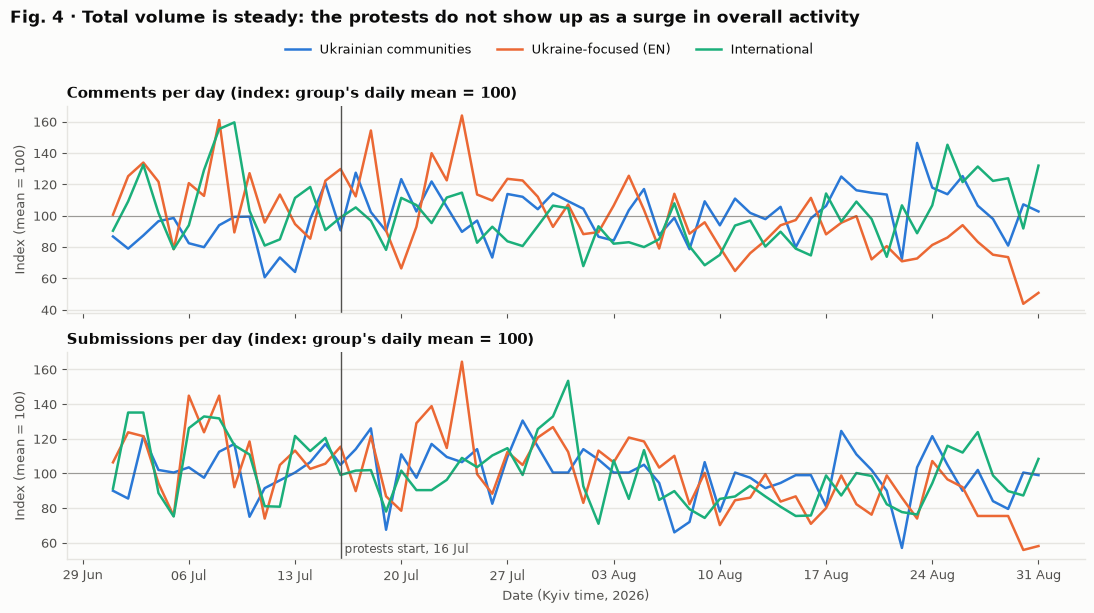

Daily comments, coefficient of variation per group: {'International': 0.2, 'Ukraine-focused (EN)': 0.25, 'Ukrainian communities': 0.17}


In [8]:
# Fig. 4 - daily activity per group, indexed to each group's own daily mean (=100)
daily_c = ds.pivot_table(index="date", columns="group", values="n", aggfunc="sum").reindex(DAYS).fillna(0)
daily_s = subs.pivot_table(index="date", columns="group", values="id", aggfunc="size").reindex(DAYS).fillna(0)
fig, axes = plt.subplots(2, 1, figsize=(11, 6.2), sharex=True)
for ax, d, ttl in zip(axes, [daily_c, daily_s], ["Comments per day", "Submissions per day"]):
    idx = d / d.mean() * 100
    for gname in GROUP_ORDER:
        ax.plot(idx.index, idx[gname], color=SERIES[gname], label=gname)
    ax.axhline(100, color=INK_2, lw=0.8, alpha=0.5); ax.axvline(PROTEST_START, color=INK_2, lw=1)
    ax.set_title(ttl + " (index: group's daily mean = 100)"); ax.set_ylabel("Index (mean = 100)"); ax.grid(axis="x", visible=False)
axes[1].text(PROTEST_START, axes[1].get_ylim()[0] + 2, " protests start, 16 Jul", fontsize=8.5, color=INK_2, va="bottom")
fig.legend(handles=[Line2D([0], [0], color=SERIES[g], label=g) for g in GROUP_ORDER], ncols=3, loc="upper center", bbox_to_anchor=(0.5, 0.945), fontsize=9)
axes[1].xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO)); axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
axes[1].set_xlabel("Date (Kyiv time, 2026)")
fig.suptitle("Fig. 4 · Total volume is steady: the protests do not show up as a surge in overall activity", x=0.01, ha="left", fontsize=12, weight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.93)); finish(fig, "fig04_daily_activity")
print("Daily comments, coefficient of variation per group:", (daily_c.std() / daily_c.mean()).round(2).to_dict())

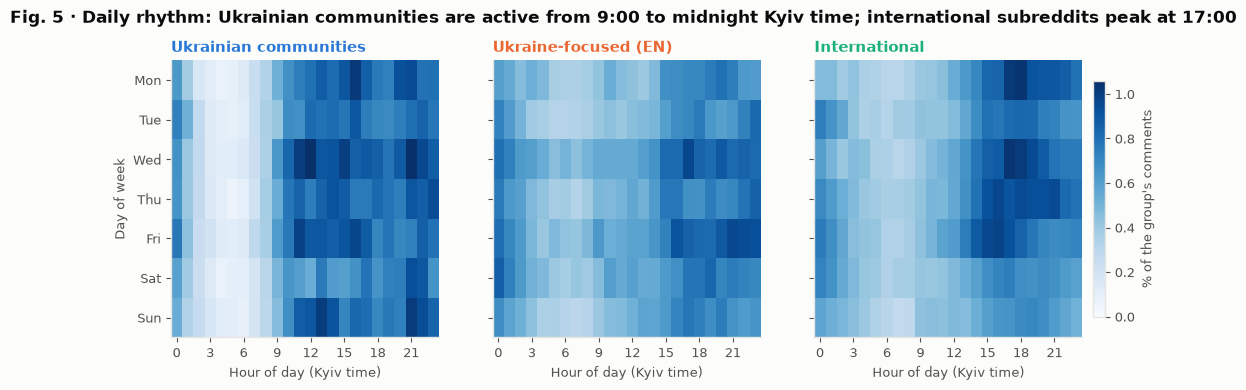

Peak hour of day (Kyiv time) per group: {'Ukrainian communities': 21, 'Ukraine-focused (EN)': 17, 'International': 17}


In [9]:
# Fig. 5 - when do people comment? weekday x hour (Kyiv time), share of each group's comments
ht = agg["hour_tab"].reset_index()
wd = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
mats = {}
for gname in GROUP_ORDER:
    m = ht[ht["group"] == gname].pivot_table(index="weekday", columns="hour", values="n", aggfunc="sum").reindex(index=range(7), columns=range(24)).fillna(0)
    mats[gname] = m / m.values.sum() * 100
vmax = max(m.values.max() for m in mats.values())
for ax, gname in zip(axes, GROUP_ORDER):
    im = ax.imshow(mats[gname].values, aspect="auto", cmap="Blues", vmin=0, vmax=vmax)
    ax.set_title(gname, color=SERIES[gname]); ax.set_xticks(range(0, 24, 3)); ax.set_yticks(range(7)); ax.set_yticklabels(wd)
    ax.set_xlabel("Hour of day (Kyiv time)"); ax.grid(False)
axes[0].set_ylabel("Day of week")
cb = fig.colorbar(im, ax=axes, shrink=0.85, pad=0.01); cb.set_label("% of the group's comments")
fig.suptitle("Fig. 5 · Daily rhythm: Ukrainian communities are active from 9:00 to midnight Kyiv time; international subreddits peak at 17:00", x=0.01, y=1.02, ha="left", fontsize=12, weight="bold")
finish(fig, "fig05_weekday_hour")
peak = {gname: int(mats[gname].sum(axis=0).idxmax()) for gname in GROUP_ORDER}
print("Peak hour of day (Kyiv time) per group:", peak)

#### 4.3.2 Authors, scores and discussion size

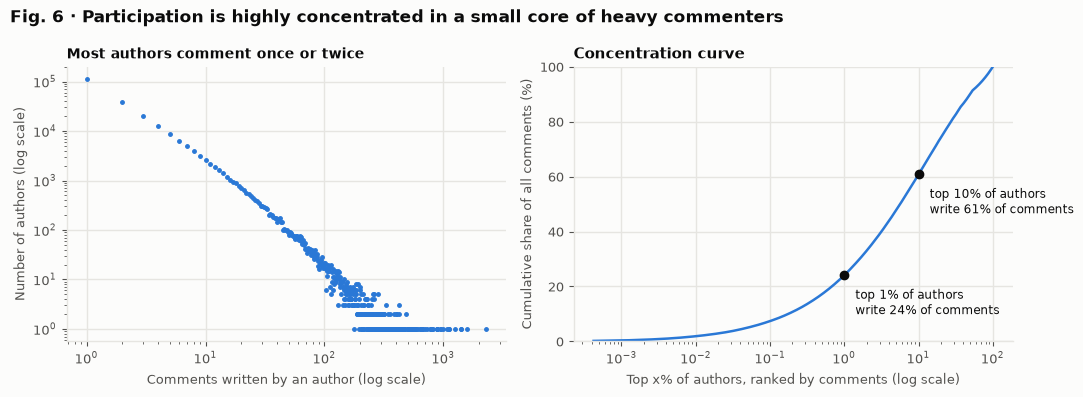

236,430 authors | 47.4% wrote exactly one comment | top 1% write 24% of comments | 4.3% of authors are active in more than one subreddit group


In [10]:
# Fig. 6 - how concentrated is participation? (authors = non-bot, non-deleted accounts)
auth = pd.Series(agg["authors"]); cnt = np.sort(auth.values)[::-1]
n_auth = len(cnt); cum = np.cumsum(cnt) / cnt.sum() * 100; xs = np.arange(1, n_auth + 1) / n_auth * 100
vc = auth.value_counts().sort_index()
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].loglog(vc.index, vc.values, ".", color=ACCENT, ms=5)
axes[0].set_xlabel("Comments written by an author (log scale)"); axes[0].set_ylabel("Number of authors (log scale)")
axes[0].set_title("Most authors comment once or twice", fontsize=10)
axes[1].plot(xs, cum, color=ACCENT); axes[1].set_xscale("log")
for p in (1, 10):
    y = np.interp(p, xs, cum); axes[1].plot([p], [y], "o", color=INK); axes[1].annotate(f"top {p}% of authors\nwrite {y:.0f}% of comments", (p, y), xytext=(8, -28), textcoords="offset points", fontsize=8.5)
axes[1].set_xlabel("Top x% of authors, ranked by comments (log scale)"); axes[1].set_ylabel("Cumulative share of all comments (%)")
axes[1].set_title("Concentration curve"); axes[1].set_ylim(0, 100)
fig.suptitle("Fig. 6 · Participation is highly concentrated in a small core of heavy commenters", x=0.01, ha="left", fontsize=12, weight="bold")
fig.tight_layout(); finish(fig, "fig06_author_concentration")
pairs = pd.DataFrame(list(agg["author_groups"]), columns=["author", "group"])
multi = pairs.groupby("author")["group"].nunique()
print(f"{n_auth:,} authors | {np.mean(cnt==1):.1%} wrote exactly one comment | top 1% write {np.interp(1, xs, cum):.0f}% of comments | "
      f"{(multi>1).mean():.1%} of authors are active in more than one subreddit group")

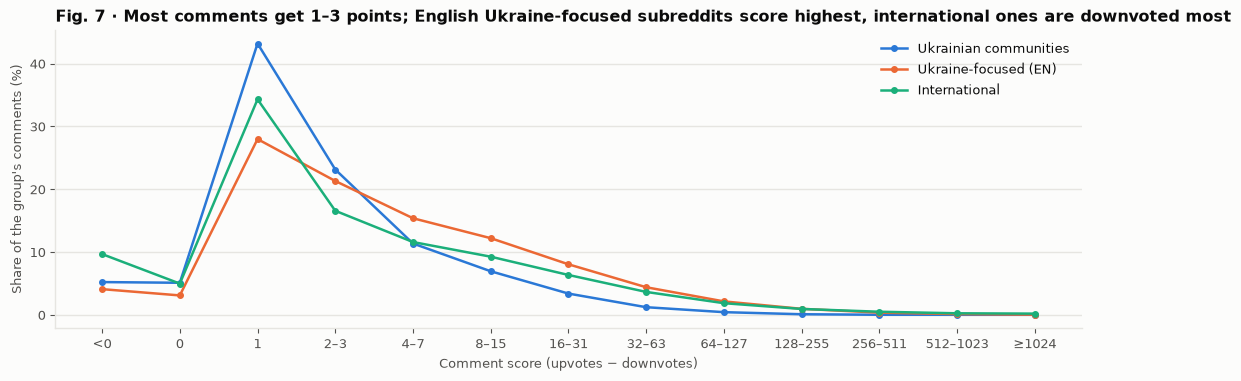

In [11]:
# Fig. 7 - comment score distribution per group
edges = [-np.inf, 0, 1, 2, 4, 8, 16, 32, 64, 128, 256, 512, 1024, np.inf]
labels = ["<0", "0", "1", "2–3", "4–7", "8–15", "16–31", "32–63", "64–127", "128–255", "256–511", "512–1023", "≥1024"]
fig, ax = plt.subplots(figsize=(11, 3.9))
for gname in GROUP_ORDER:
    sc = pd.Series(agg["score_hist"][gname])
    binned = sc.groupby(pd.cut(sc.index, edges, right=False, labels=labels), observed=False).sum()
    ax.plot(labels, binned / binned.sum() * 100, "o-", color=SERIES[gname], label=gname, ms=4)
ax.set_xlabel("Comment score (upvotes − downvotes)"); ax.set_ylabel("Share of the group's comments (%)")
ax.set_title("Fig. 7 · Most comments get 1–3 points; English Ukraine-focused subreddits score highest, international ones are downvoted most", loc="left", fontsize=11.5, weight="bold")
ax.legend(); ax.grid(axis="x", visible=False); fig.tight_layout(); finish(fig, "fig07_score_distribution")

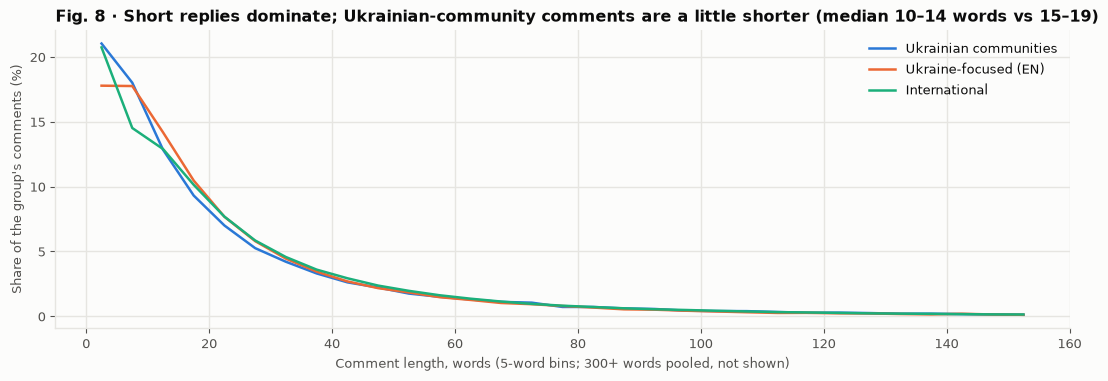

In [12]:
# Fig. 8 - comment length (words) per group
fig, ax = plt.subplots(figsize=(11, 3.9))
for gname in GROUP_ORDER:
    lh = pd.Series(agg["len_hist"][gname]).sort_index(); lh = lh[lh.index <= 150]
    tot = sum(agg["len_hist"][gname].values())
    ax.plot(lh.index + 2.5, lh.values / tot * 100, color=SERIES[gname], label=gname)
ax.set_xlabel("Comment length, words (5-word bins; 300+ words pooled, not shown)"); ax.set_ylabel("Share of the group's comments (%)")
ax.set_title("Fig. 8 · Short replies dominate; Ukrainian-community comments are a little shorter (median 10–14 words vs 15–19)", loc="left", fontsize=11.5, weight="bold")
ax.legend(); fig.tight_layout(); finish(fig, "fig08_comment_length")

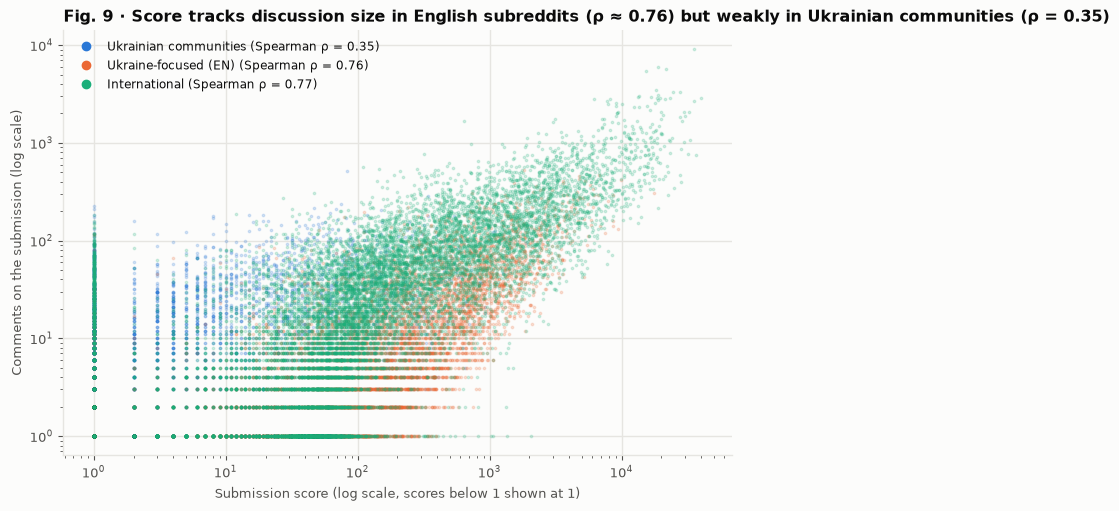

In [13]:
# Fig. 9 - submissions: popularity (score) vs discussion size (num_comments)
fig, ax = plt.subplots(figsize=(7.5, 5.2))
rho = {}
for gname in GROUP_ORDER:
    d = subs[subs["group"] == gname]
    ax.scatter(d["score"].clip(lower=1), d["num_comments"].clip(lower=1), s=3, alpha=0.18, color=SERIES[gname], rasterized=True)
    rho[gname] = stats.spearmanr(d["score"], d["num_comments"])[0]
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Submission score (log scale, scores below 1 shown at 1)"); ax.set_ylabel("Comments on the submission (log scale)")
ax.legend(handles=[Line2D([0], [0], marker="o", ls="", color=SERIES[g], label=f"{g} (Spearman ρ = {rho[g]:.2f})") for g in GROUP_ORDER], loc="upper left", fontsize=8.5)
ax.set_title("Fig. 9 · Score tracks discussion size in English subreddits (ρ ≈ 0.76) but weakly in Ukrainian communities (ρ = 0.35)", loc="left", fontsize=11.5, weight="bold")
fig.tight_layout(); finish(fig, "fig09_score_vs_comments")

A caution before moving on: submission scores in Ukrainian communities look like early snapshots (many posts sit at score = 1 despite up to ~200 comments), so we do not compare scores across groups.

### 4.4 Combining submissions and comments

Submissions and comments were analysed separately above; here they meet. They are **joined on the thread key**: a comment's `link_id` (`t3_<id>`) equals the submission's `id`. We need the join for two reasons — to attach titles and dates to comments, which lets us name the threads that carried the discussion (Fig. 15), and to check completeness by comparing reported and collected comment counts (Fig. 10). Because the comment file is too large to hold in memory together with texts, the join works with per-thread comment counts.

In [14]:
# MERGE: comment.link_id ("t3_<id>") == submission.id  -> number of collected comments per submission
thr = pd.Series(agg["threads"], name="collected")
subs["collected"] = ("t3_" + subs["id"]).map(thr).fillna(0).astype(int)
in_subs = set("t3_" + subs["id"])
matched = int(sum(v for k, v in agg["threads"].items() if k in in_subs))
total_h = int(sum(agg["threads"].values()))
print(f"Comment->submission join: {matched:,} of {total_h:,} non-bot comments ({matched/total_h:.1%}) belong to a submission present in our data.")
print(f"Submissions with at least one collected comment: {(subs['collected']>0).mean():.1%}")
merged_preview = (subs.sort_values("collected", ascending=False)
                  [["subreddit", "date_local", "title", "score", "num_comments", "collected"]].head(8).rename(columns={"num_comments": "num_comments (reported)", "collected": "comments (collected)"}))
display(merged_preview)

Comment->submission join: 1,434,919 of 1,449,147 non-bot comments (99.0%) belong to a submission present in our data.
Submissions with at least one collected comment: 68.6%


,subreddit,date_local,title,score,num_comments (reported),comments (collected)
1429,worldnews,2026-07-03,"Russia planning attack on Poland to test Nato resolve, US warns",35607,9060,10089
29280,worldnews,2026-08-22,"Canadian prime minister suspends trade talks with U.S., setting new 50% tariffs in motion",18736,6026,6600
505,worldnews,2026-07-01,/r/WorldNews Discussion Thread: US and Israel launch attack on Iran; Iran retaliates (...,101,171,6277
26850,worldnews,2026-08-17,Trump threatens to bomb Oman over Iran deal,21810,5688,6073
13517,worldnews,2026-07-24,/r/WorldNews Discussion Thread: US and Israel launch attack on Iran; Iran retaliates (...,109,565,5663
32313,worldnews,2026-08-27,Trump signs order renaming Lake Ontario as 'Lake America' in the United States,15300,5384,5658
2222,worldnews,2026-07-04,"Germany changes sick leave policy: 'We are abolishing sick leave by phone,' says Chanc...",18040,3450,3656
4645,worldnews,2026-07-08,Trump orders cutoff of 'all' US trade with Spain,27629,3348,3533


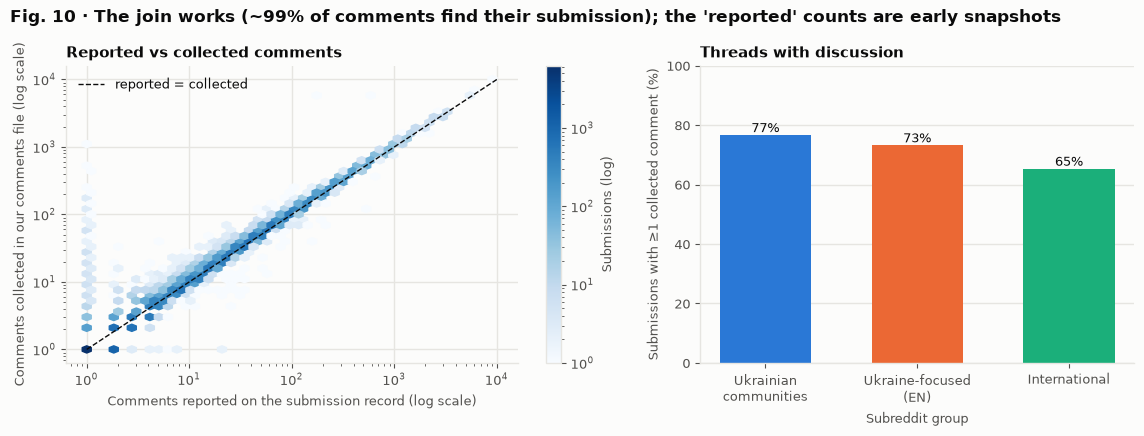

Collected / reported comments overall: 1.07 (>1 means threads kept growing after the submission record was captured)
Share of submissions where collected > reported: 37.8%


In [15]:
# Fig. 10 - merge quality: reported vs collected comment counts per submission
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4), gridspec_kw={"width_ratios": [1.3, 1]})
d = subs[(subs["num_comments"] > 0) | (subs["collected"] > 0)]
hb = axes[0].hexbin(d["num_comments"].clip(lower=1), d["collected"].clip(lower=1), gridsize=45, xscale="log", yscale="log", bins="log", cmap="Blues", mincnt=1)
lim = [1, max(d["num_comments"].max(), d["collected"].max())]
axes[0].plot(lim, lim, color=INK, lw=1, ls="--", label="reported = collected")
axes[0].set_xlabel("Comments reported on the submission record (log scale)"); axes[0].set_ylabel("Comments collected in our comments file (log scale)")
axes[0].set_title("Reported vs collected comments"); axes[0].legend(loc="upper left"); fig.colorbar(hb, ax=axes[0], label="Submissions (log)")
share = subs.groupby("group")["collected"].apply(lambda s: (s > 0).mean() * 100).reindex(GROUP_ORDER)
axes[1].bar(range(3), share.values, color=[SERIES[g] for g in GROUP_ORDER], width=0.6)
for i, v in enumerate(share.values): axes[1].text(i, v + 1, f"{v:.0f}%", ha="center", fontsize=9)
axes[1].set_xticks(range(3)); axes[1].set_xticklabels(["Ukrainian\ncommunities", "Ukraine-focused\n(EN)", "International"])
axes[1].set_xlabel("Subreddit group"); axes[1].set_ylabel("Submissions with ≥1 collected comment (%)"); axes[1].set_ylim(0, 100); axes[1].set_title("Threads with discussion"); axes[1].grid(axis="x", visible=False)
fig.suptitle("Fig. 10 · The join works (~99% of comments find their submission); the 'reported' counts are early snapshots", x=0.01, ha="left", fontsize=12, weight="bold")
fig.tight_layout(); finish(fig, "fig10_merge_quality")
r = (d["collected"].sum() / d["num_comments"].sum())
print(f"Collected / reported comments overall: {r:.2f} (>1 means threads kept growing after the submission record was captured)")
print("Share of submissions where collected > reported:", f"{(d['collected'] > d['num_comments']).mean():.1%}")

The join works: 99.0% of non-bot comments belong to a submission in our data. Collected counts exceed the reported `num_comments` for 38% of submissions (1.07× overall), which shows that `num_comments` is an early snapshot, so we rely on the collected counts.

### 4.5 The event: 15–20 July 2026

Now to the protests themselves. Reddit users wrote 3,170 comments mentioning Fedorov, 1,337 of them inside the window.

#### 4.5.1 Timing: online first, posters later

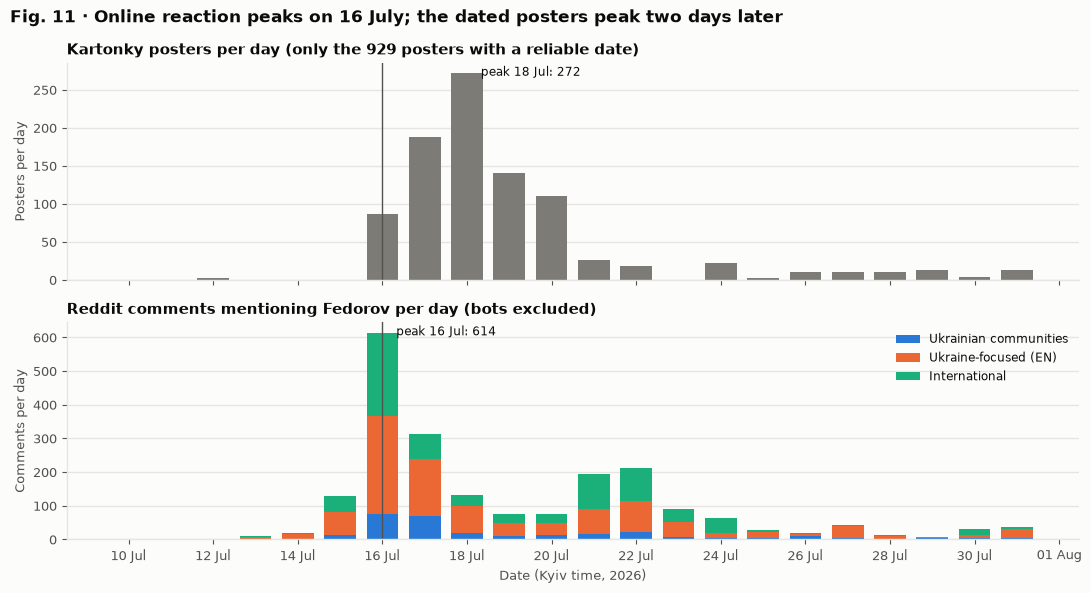

Peak day, posters: 2026-07-18 | peak day, Reddit: 2026-07-16


In [16]:
# Fig. 11 - offline vs online around the protests: posters with a reliable date vs Reddit comments mentioning Fedorov
win = pd.date_range("2026-07-10", "2026-07-31")
kr = kart[kart["date_reliable"].astype(str) == "True"].assign(day=lambda x: pd.to_datetime(x["date_local"]))
k_day = kr.groupby("day").size().reindex(win, fill_value=0)
fed_g = agg["kw_day"]["Fedorov"].unstack("group").fillna(0)
fed_g.index = pd.to_datetime(fed_g.index); fed_g = fed_g.reindex(win, fill_value=0)[GROUP_ORDER]
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
axes[0].bar(k_day.index, k_day.values, color="#7d7b76", width=0.75)
axes[0].set_title(f"Kartonky posters per day (only the {int(k_day.sum())} posters with a reliable date)"); axes[0].set_ylabel("Posters per day")
bottom = np.zeros(len(win))
for gname in GROUP_ORDER:
    axes[1].bar(win, fed_g[gname].values, bottom=bottom, color=SERIES[gname], width=0.75, label=gname); bottom += fed_g[gname].values
axes[1].set_title("Reddit comments mentioning Fedorov per day (bots excluded)"); axes[1].set_ylabel("Comments per day"); axes[1].legend(loc="upper right", fontsize=8.5)
for ax in axes:
    ax.axvline(PROTEST_START, color=INK_2, lw=1); ax.grid(axis="x", visible=False)
for ax, s_ in [(axes[0], k_day), (axes[1], fed_g.sum(axis=1))]:
    d_ = s_.idxmax(); ax.annotate(f"peak {d_:%d %b}: {int(s_.max())}", (d_, s_.max()), xytext=(10, -2), textcoords="offset points", fontsize=8.5)
axes[1].xaxis.set_major_locator(mdates.DayLocator(interval=2)); axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b")); axes[1].set_xlabel("Date (Kyiv time, 2026)")
fig.suptitle("Fig. 11 · Online reaction peaks on 16 July; the dated posters peak two days later", x=0.01, ha="left", fontsize=12, weight="bold")
fig.tight_layout(); finish(fig, "fig11_offline_vs_online")
print("Peak day, posters:", k_day.idxmax().date(), "| peak day, Reddit:", fed_g.sum(axis=1).idxmax().date())

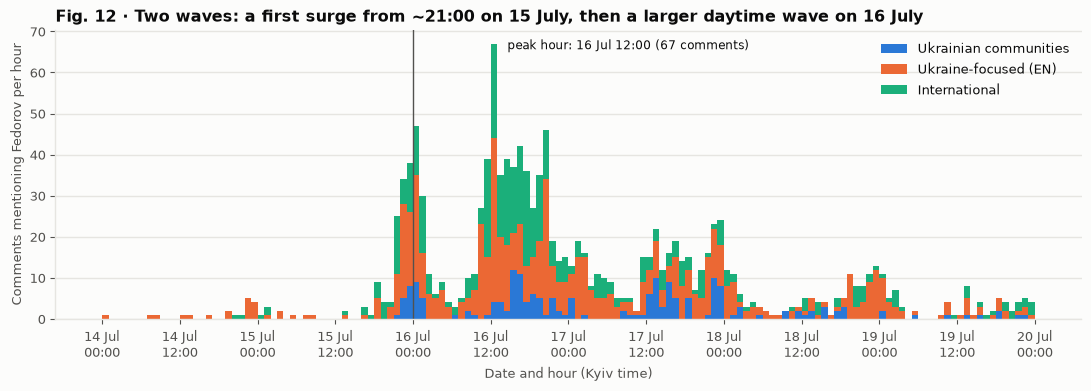

First hour with >=20 Fedorov comments: 2026-07-15 21:00:00


In [17]:
# Fig. 12 - hour-by-hour reaction, 14-19 July (Kyiv time)
fh = agg["fed_hourly"].unstack("group").fillna(0)
fh.index = pd.to_datetime(fh.index + ":00")
hrs = pd.date_range("2026-07-14 00:00", "2026-07-19 23:00", freq="60min")
fh = fh.reindex(hrs, fill_value=0)[GROUP_ORDER]
fig, ax = plt.subplots(figsize=(11, 4))
bottom = np.zeros(len(hrs))
for gname in GROUP_ORDER:
    ax.bar(hrs, fh[gname].values, bottom=bottom, width=1 / 24, color=SERIES[gname], label=gname, align="edge"); bottom += fh[gname].values
ph = fh.sum(axis=1).idxmax(); ax.annotate(f"peak hour: {ph:%d %b %H:00} ({int(fh.sum(axis=1).max())} comments)", (ph, fh.sum(axis=1).max()), xytext=(12, -4), textcoords="offset points", fontsize=8.5)
ax.axvline(pd.Timestamp("2026-07-16 00:00"), color=INK_2, lw=1)
ax.xaxis.set_major_locator(mdates.HourLocator(byhour=[0, 12])); ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b\n%H:00"))
ax.set_xlabel("Date and hour (Kyiv time)"); ax.set_ylabel("Comments mentioning Fedorov per hour"); ax.legend(loc="upper right"); ax.grid(axis="x", visible=False)
ax.set_title("Fig. 12 · Two waves: a first surge from ~21:00 on 15 July, then a larger daytime wave on 16 July", loc="left", fontsize=11.5, weight="bold")
fig.tight_layout(); finish(fig, "fig12_hourly_reaction")
first_surge = fh.sum(axis=1)[fh.sum(axis=1) >= 20].index.min()
print("First hour with >=20 Fedorov comments:", first_surge)

#### 4.5.2 Where, who and which threads

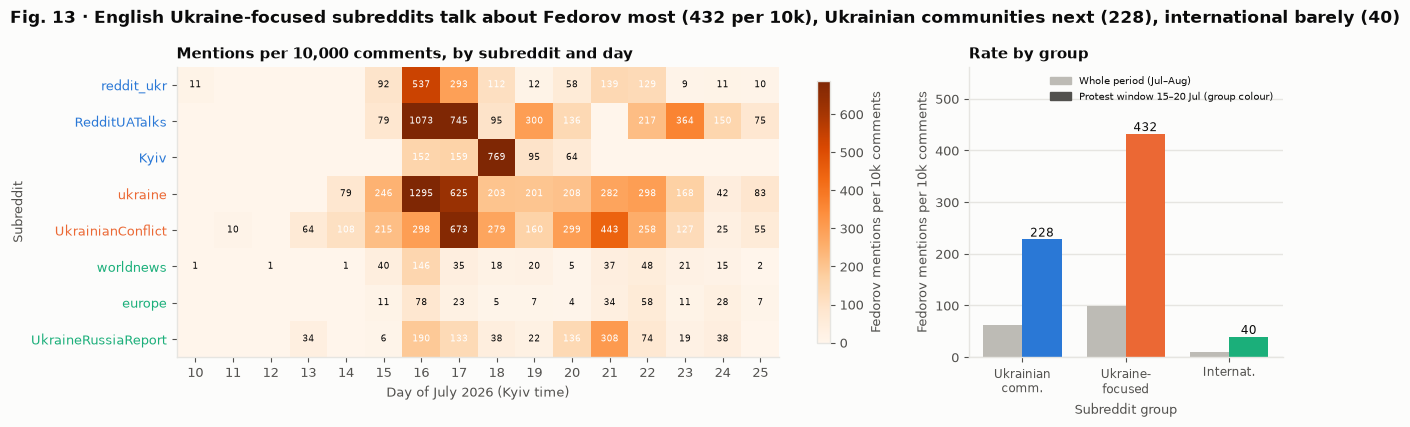

{'Ukrainian communities': 228.3, 'Ukraine-focused (EN)': 432.4, 'International': 39.8}


In [18]:
# Fig. 13 - intensity of the Fedorov discourse: subreddit x day heatmap and group-level rate
sel = ds[(ds["date_local"] >= "2026-07-10") & (ds["date_local"] <= "2026-07-25")]
fed_m = sel.pivot_table(index="subreddit", columns="date_local", values="fed", aggfunc="sum")
hum_m = sel.pivot_table(index="subreddit", columns="date_local", values="human", aggfunc="sum")
rate = (fed_m / hum_m * 1e4).reindex(SUB_ORDER)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), gridspec_kw={"width_ratios": [2.4, 1]})
im = axes[0].imshow(rate.values, aspect="auto", cmap="Oranges", vmin=0, vmax=np.nanpercentile(rate.values, 97))
axes[0].set_yticks(range(len(SUB_ORDER))); axes[0].set_yticklabels(SUB_ORDER)
for t_, s_ in zip(axes[0].get_yticklabels(), SUB_ORDER): t_.set_color(SERIES[GROUPS[s_]])
axes[0].set_xticks(range(rate.shape[1])); axes[0].set_xticklabels([c[8:] for c in rate.columns]); axes[0].set_xlabel("Day of July 2026 (Kyiv time)"); axes[0].set_ylabel("Subreddit"); axes[0].grid(False)
for i in range(rate.shape[0]):
    for j in range(rate.shape[1]):
        v = rate.values[i, j]
        if v > 0: axes[0].text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=6.5, color=INK if v < np.nanpercentile(rate.values, 70) else "white")
fig.colorbar(im, ax=axes[0], label="Fedorov mentions per 10k comments", shrink=0.9)
axes[0].set_title("Mentions per 10,000 comments, by subreddit and day")
gt = ds.groupby("group")[["human", "fed"]].sum().reindex(GROUP_ORDER)
gw = ds[(ds["date_local"] >= "2026-07-15") & (ds["date_local"] <= "2026-07-20")].groupby("group")[["human", "fed"]].sum().reindex(GROUP_ORDER)
x = np.arange(3); w = 0.38
axes[1].bar(x - w / 2, gt["fed"] / gt["human"] * 1e4, w, color="#bdbbb5")
axes[1].bar(x + w / 2, gw["fed"] / gw["human"] * 1e4, w, color=[SERIES[g] for g in GROUP_ORDER])
axes[1].legend(handles=[Patch(color="#bdbbb5", label="Whole period (Jul–Aug)"), Patch(color=INK_2, label="Protest window 15–20 Jul (group colour)")], fontsize=7.5, loc="upper right", bbox_to_anchor=(1.0, 1.0))
axes[1].set_ylim(0, (gw["fed"] / gw["human"] * 1e4).max() * 1.3)
for xi, v in zip(x + w / 2, gw["fed"] / gw["human"] * 1e4): axes[1].text(xi, v + 5, f"{v:.0f}", ha="center", fontsize=8.5)
axes[1].set_xticks(x); axes[1].set_xticklabels(["Ukrainian\ncomm.", "Ukraine-\nfocused", "Internat."], fontsize=8.5); axes[1].set_xlabel("Subreddit group"); axes[1].set_ylabel("Fedorov mentions per 10k comments"); axes[1].set_title("Rate by group"); axes[1].grid(axis="x", visible=False)
fig.suptitle("Fig. 13 · English Ukraine-focused subreddits talk about Fedorov most (432 per 10k), Ukrainian communities next (228), international barely (40)", x=0.01, ha="left", fontsize=12, weight="bold")
fig.tight_layout(); finish(fig, "fig13_fedorov_intensity")
print((gw["fed"] / gw["human"] * 1e4).round(1).to_dict())

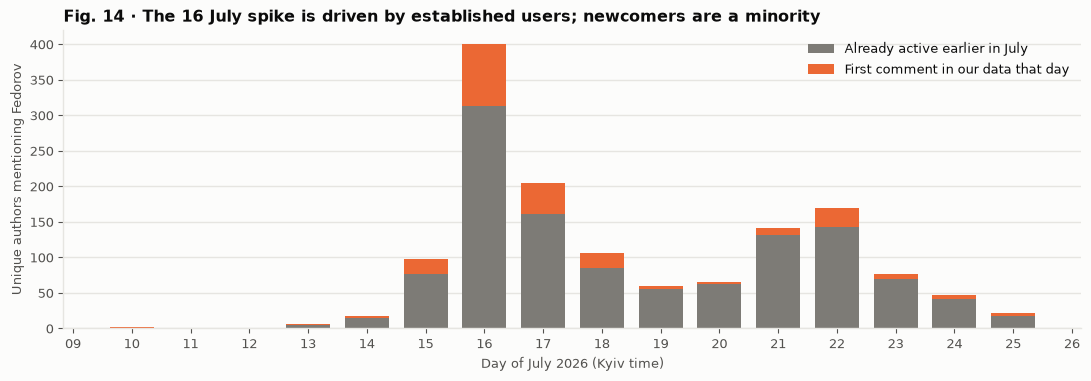

Newcomer share on 16 Jul: 21.8% | Jul 10-14 mean: 18.5%


In [19]:
# Fig. 14 - who talks about Fedorov: newcomers vs already-active authors
fca = agg["fed_comments"]; fc = fca[fca["author"] != "[deleted]"].copy()
fc["first_seen"] = fc["author"].map(agg["author_first"]); fc["newcomer"] = fc["first_seen"] == fc["date_local"]
dd = fc.drop_duplicates(["author", "date_local"]).groupby(["date_local", "newcomer"]).size().unstack(fill_value=0)
dd.index = pd.to_datetime(dd.index); dd = dd.reindex(pd.date_range("2026-07-10", "2026-07-25"), fill_value=0)
fig, ax = plt.subplots(figsize=(11, 3.9))
ax.bar(dd.index, dd.get(False, 0), color="#7d7b76", width=0.75, label="Already active earlier in July")
ax.bar(dd.index, dd.get(True, 0), bottom=dd.get(False, 0), color="#eb6834", width=0.75, label="First comment in our data that day")
ax.xaxis.set_major_locator(mdates.DayLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%d")); ax.set_xlabel("Day of July 2026 (Kyiv time)")
ax.set_ylabel("Unique authors mentioning Fedorov"); ax.legend(); ax.grid(axis="x", visible=False)
ax.set_title("Fig. 14 · The 16 July spike is driven by established users; newcomers are a minority", loc="left", fontsize=11.5, weight="bold")
fig.tight_layout(); finish(fig, "fig14_newcomers")
tot = dd.sum(axis=1); print("Newcomer share on 16 Jul:", f"{dd.get(True, 0).loc['2026-07-16'] / tot.loc['2026-07-16']:.1%}", "| Jul 10-14 mean:", f"{(dd.get(True,0).loc[:'2026-07-14'].sum() / tot.loc[:'2026-07-14'].sum()):.1%}")

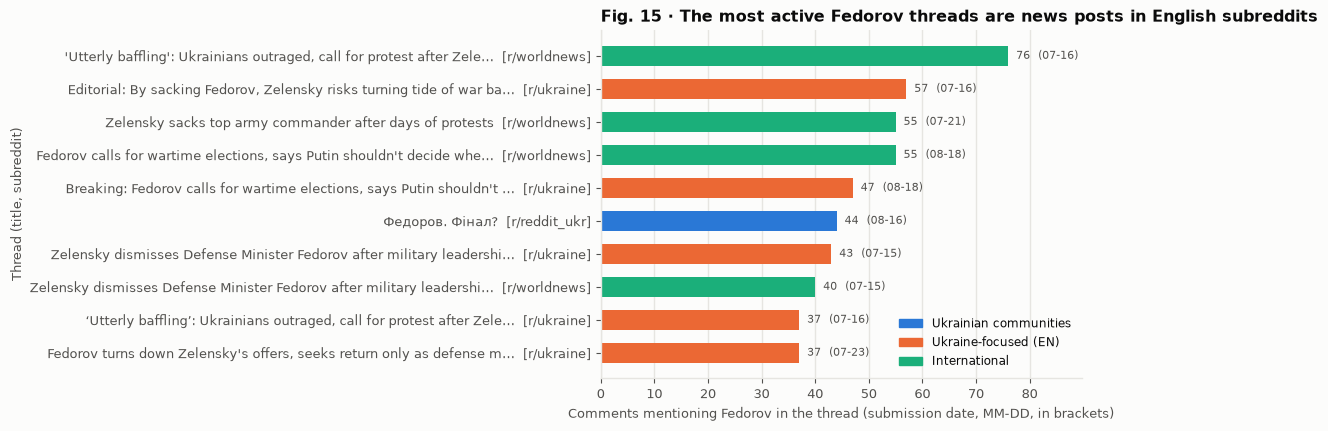

In [20]:
# Fig. 15 - which threads carried the discussion? (merge: Fedorov comments -> submissions)
meta = subs.set_index("id")
top = fca.groupby("link_id").size().sort_values(ascending=False).head(10)
rows = []
for lid, c in top.items():
    sid = lid[3:]
    title = meta["title"].get(sid, "(submission not in our data)")
    sub = meta["subreddit"].get(sid, fca.loc[fca["link_id"] == lid, "subreddit"].iloc[0])
    rows.append((f"{title[:68]}{'…' if len(title) > 68 else ''}  [r/{sub}]", c, GROUPS[sub], meta["date_local"].get(sid, "")))
tt = pd.DataFrame(rows, columns=["label", "n", "group", "date"]).iloc[::-1]
fig, ax = plt.subplots(figsize=(11, 4.4))
ax.barh(tt["label"], tt["n"], color=[SERIES[g] for g in tt["group"]], height=0.6)
for y, (v, dte) in enumerate(zip(tt["n"], tt["date"])): ax.text(v, y, f"  {v}  ({dte[5:]})", va="center", fontsize=8, color=INK_2)
ax.set_ylabel("Thread (title, subreddit)"); ax.set_xlim(0, tt["n"].max() * 1.18); ax.set_xlabel("Comments mentioning Fedorov in the thread (submission date, MM-DD, in brackets)"); ax.grid(axis="y", visible=False)
group_legend(ax, loc="lower right", fontsize=8.5)
ax.set_title("Fig. 15 · The most active Fedorov threads are news posts in English subreddits", loc="left", fontsize=11.5, weight="bold")
fig.tight_layout(); finish(fig, "fig15_top_threads")

Taken together, the figures tell a clear story. Reddit reacts first: 129 comments mention Fedorov on 15 July and **614 on 16 July**, with the first surge at 21:00 on 15 July, while dated posters peak two days later, on 18 July. The reaction is strongly community-specific: per 10,000 comments in the window, the English-language Ukraine-focused subreddits reach 432 mentions, Ukrainian communities 228 and international subreddits only 40 (the 769 of r/Kyiv on 18 July comes from a tiny denominator). It is also made by established users, since 78% of the authors who mention Fedorov on 16 July had already commented earlier in July. Finally, the secondary waves of 21–22 July and mid-August sit on threads about the army commander's dismissal and Fedorov's call for wartime elections — the leads for **H3**, which the news data will have to confirm.

### 4.6 Content analysis

#### 4.6.1 Topic trends

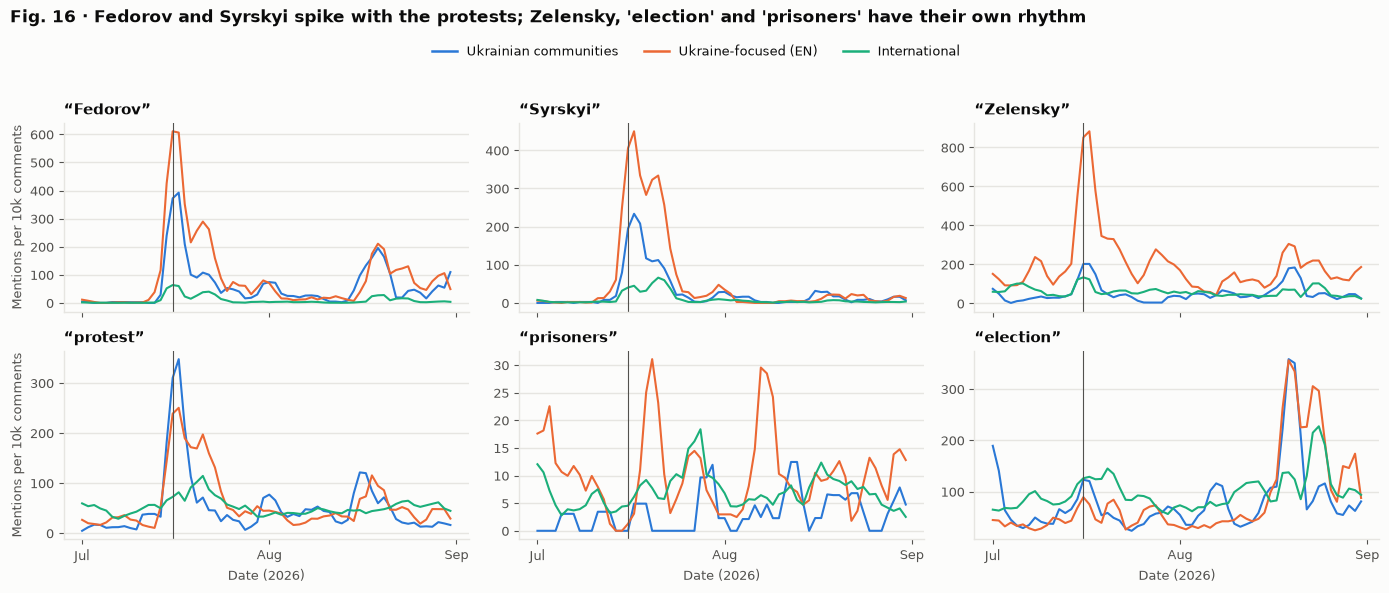

In [21]:
# Fig. 16 - topic trends: daily mentions of key terms per 10k comments, 3-day moving average
hum_day = ds.pivot_table(index="date_local", columns="group", values="human", aggfunc="sum")
kw = agg["kw_day"].copy()
names = list(kw.columns)
fig, axes = plt.subplots(2, 3, figsize=(14, 6), sharex=True)
for ax, nm in zip(axes.ravel(), names):
    piv = kw[nm].unstack("group").reindex(hum_day.index).fillna(0)
    r_ = (piv / hum_day * 1e4).rolling(3, center=True, min_periods=1).mean()
    r_.index = pd.to_datetime(r_.index); r_ = r_.reindex(DAYS)
    for gname in GROUP_ORDER: ax.plot(r_.index, r_[gname], color=SERIES[gname], lw=1.5)
    ax.axvline(PROTEST_START, color=INK_2, lw=0.8); ax.set_title(f"“{nm}”"); ax.grid(axis="x", visible=False)
    ax.xaxis.set_major_locator(mdates.MonthLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
for ax in axes[:, 0]: ax.set_ylabel("Mentions per 10k comments")
for ax in axes[1]: ax.set_xlabel("Date (2026)")
fig.legend(handles=[Line2D([0], [0], color=SERIES[g], label=g) for g in GROUP_ORDER], ncols=3, loc="upper center", bbox_to_anchor=(0.5, 0.94), fontsize=9)
fig.suptitle("Fig. 16 · Fedorov and Syrskyi spike with the protests; Zelensky, 'election' and 'prisoners' have their own rhythm", x=0.01, ha="left", fontsize=12, weight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.9)); finish(fig, "fig16_keyword_trends")

#### 4.6.2 What do posters and comments say?

The next figure counts the most frequent bigrams, once per document and after removing stop-words.

In [22]:
# ---------- text processing helpers (poster + Reddit) ----------
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
from sklearn.preprocessing import normalize

UA_STOP = set("""на не за це ми що до та як про для або з і у в а є то чи щоб але якщо від цей ця ці ти ви тут ж ну так все вже його її їх
він вона вони мене мені тебе нас вас бо ще був була були буде тільки лише коли де там цього цьому який яка які при по без між над під
вам нам їм ні да б би той те хоч ніж навіть може можна треба просто дуже мав має тому й із зі ось себе собі свій своє цим цих ним них
сам вся всі весь також якщо тож ж ось ото""".split())
NOISE = set("""https http www com org en reddit removed deleted gt amp preview redd webp format pjpg jpeg width png gif giphy bsky app profile
just like don ll ve re didn isn doesn won can one get would even also really think know going said say yeah people amp x200b edit""".split())
STOP = set(ENGLISH_STOP_WORDS) | UA_STOP | NOISE
URL_RE = re.compile(r"https?://\S+|www\.\S+")
TOK_RE = re.compile(r"[a-zа-яіїєґ'’]+")
CYR_RE, LAT_RE = re.compile(r"[Ѐ-ӿ]"), re.compile(r"[A-Za-z]")

def canon(t):                     # unify key entities across Latin/Cyrillic spellings (used for cross-language similarity)
    for stems, c in ((("федоров", "fedorov", "fedorow"), "fedorov"), (("сирськ", "syrsk"), "syrskyi"),
                     (("зеленськ", "zelensk"), "zelensky"), (("путін", "putin"), "putin"), (("україн", "ukrain"), "ukraine")):
        if t.startswith(stems): return c
    return t

def tokens(text, unify=False):
    out = [t.strip("'’") for t in TOK_RE.findall(URL_RE.sub(" ", str(text).lower()))]
    out = [t for t in out if len(t) > 1]
    return [canon(t) for t in out] if unify else out

def bigrams_df(docs, topn=8):    # document frequency of bigrams (stop-words removed first, so 'defense minister' is adjacent)
    c = Counter()
    for toks in docs:
        k = [t for t in toks if t not in STOP]
        c.update(set(f"{a} {b}" for a, b in zip(k, k[1:])))
    return c.most_common(topn)

def is_cyr(text):
    return len(CYR_RE.findall(text)) > len(LAT_RE.findall(text))

W0, W1 = "2026-07-15", "2026-07-20"
posters_win = kart[(kart["date_local"] >= W0) & (kart["date_local"] <= W1) & kart["has_text"].astype(str).eq("True")]
fed_win = fca[(fca["date_local"] >= W0) & (fca["date_local"] <= W1)].copy()
base_win = agg["baseline_window"].copy()
for d_ in (fed_win, base_win): d_["cyr"] = d_["body"].map(is_cyr)
print(f"Posters in window: {len(posters_win):,} | Fedorov comments in window: {len(fed_win):,} "
      f"({fed_win['cyr'].mean():.0%} Cyrillic) | baseline comments (15% sample of the rest): {len(base_win):,}")
display(fed_win.groupby("group").agg(comments=("id", "size"), share_cyrillic=("cyr", "mean")).reindex(GROUP_ORDER).round(2))

Posters in window: 3,374 | Fedorov comments in window: 1,337 (15% Cyrillic) | baseline comments (15% sample of the rest): 18,253


,comments,share_cyrillic
group,,
Ukrainian communities,200,0.96
Ukraine-focused (EN),682,0.00
International,455,0.00


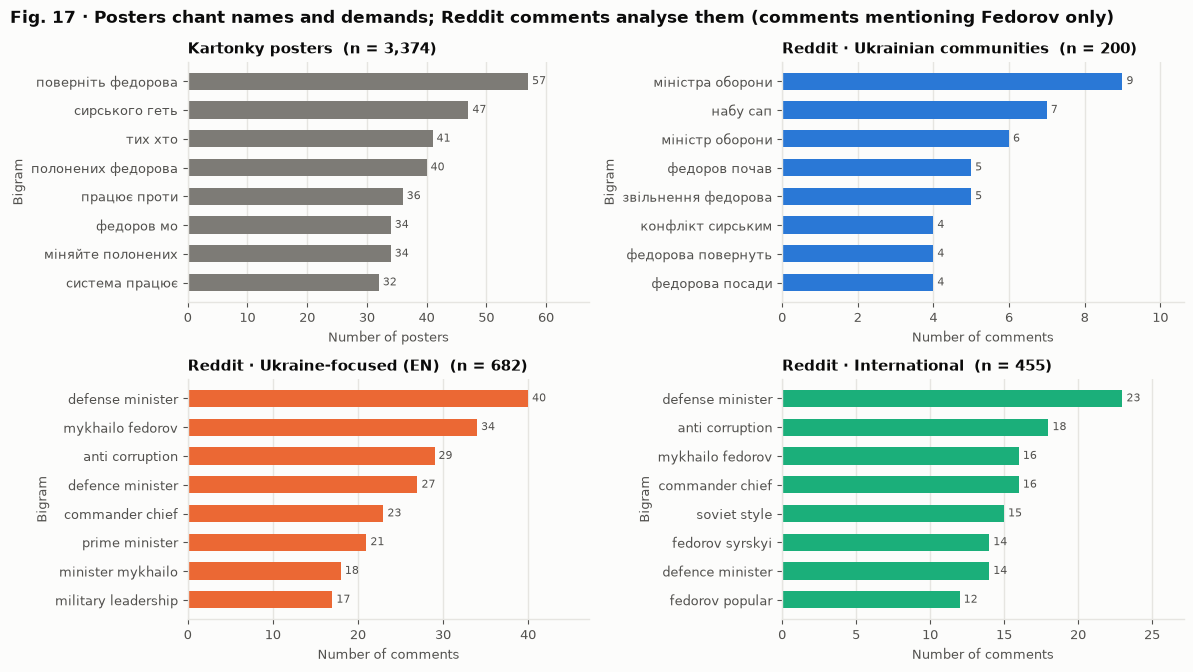

In [23]:
# Fig. 17 - what do posters and comments say? top bigrams (document frequency) during 15-20 July
panels = [("Kartonky posters", [tokens(t) for t in posters_win["text"]], "#7d7b76")]
for gname in GROUP_ORDER:
    panels.append((f"Reddit · {gname}", [tokens(t) for t in fed_win.loc[fed_win["group"] == gname, "body"]], SERIES[gname]))
fig, axes = plt.subplots(2, 2, figsize=(12, 6.8))
for ax, (ttl, docs, col) in zip(axes.ravel(), panels):
    bg = bigrams_df(docs, 8)[::-1]
    ax.barh([b for b, _ in bg], [c for _, c in bg], color=col, height=0.6)
    for y, (_, c) in enumerate(bg): ax.text(c, y, f" {c}", va="center", fontsize=8, color=INK_2)
    ax.set_title(f"{ttl}  (n = {len(docs):,})"); ax.set_xlabel("Number of posters" if "poster" in ttl else "Number of comments"); ax.set_ylabel("Bigram"); ax.grid(axis="y", visible=False)
    ax.set_xlim(0, max(c for _, c in bg) * 1.18)
fig.suptitle("Fig. 17 · Posters chant names and demands; Reddit comments analyse them (comments mentioning Fedorov only)", x=0.01, ha="left", fontsize=12, weight="bold")
fig.tight_layout(); finish(fig, "fig17_bigrams")

#### 4.6.3 H1: how close are the vocabularies?

To test H1 we compare the TF-IDF centroid of the posters with those of several comment corpora, using cosine similarity. Key names are unified across scripts, and the word *Fedorov* is removed because it would inflate the overlap trivially. Intervals are 95% bootstrap intervals.

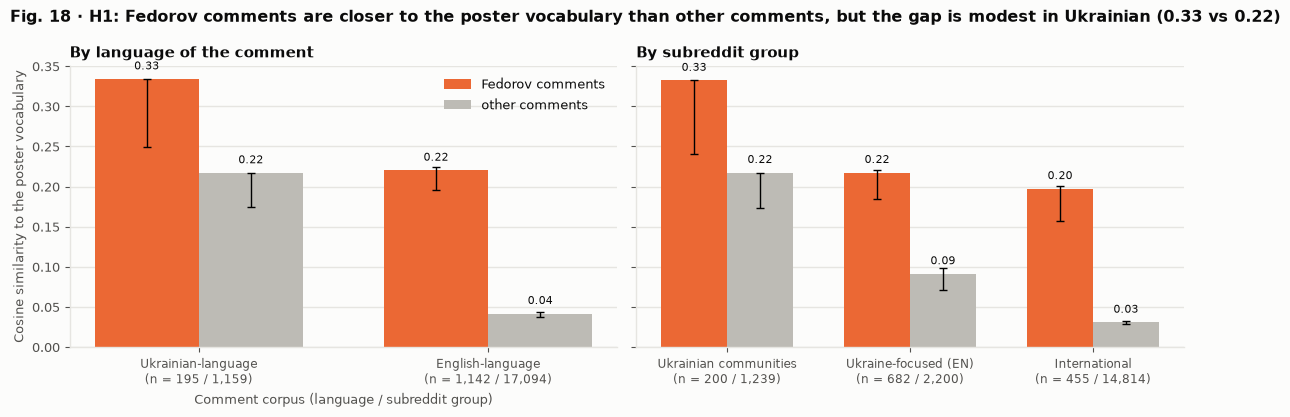

In [24]:
# Fig. 18 - H1: lexical similarity between posters and Reddit (TF-IDF centroids, cosine; names unified across scripts)
def doc_terms(toks):
    k = [t for t in toks if t not in STOP and t != "fedorov"]      # 'fedorov' is excluded: it is the selection criterion of the Fedorov comments and would inflate the overlap trivially
    return k + [f"{a} {b}" for a, b in zip(k, k[1:])]

corp = {"posters": [tokens(t, True) for t in posters_win["text"]]}
def add(name, df_): corp[name] = [tokens(t, True) for t in df_["body"]]
for lang, flag in (("Ukrainian-language", True), ("English-language", False)):
    add((lang, "Fedorov comments"), fed_win[fed_win["cyr"] == flag]); add((lang, "other comments"), base_win[base_win["cyr"] == flag])
for gname in GROUP_ORDER:
    add((gname, "Fedorov comments"), fed_win[fed_win["group"] == gname]); add((gname, "other comments"), base_win[base_win["group"] == gname])
allk = list(corp); alldocs = [d for k_ in allk for d in corp[k_]]
vec = TfidfVectorizer(analyzer=doc_terms, sublinear_tf=True, min_df=2); X = vec.fit_transform(alldocs)
bounds = np.cumsum([0] + [len(corp[k_]) for k_ in allk]); sl = {k_: slice(bounds[i], bounds[i + 1]) for i, k_ in enumerate(allk)}
cent = lambda M: normalize(np.asarray(M.mean(axis=0)))
pc = cent(X[sl["posters"]])
rng = np.random.default_rng(0)
def sim(k_, boot=300):
    M = X[sl[k_]]; s = float((cent(M) @ pc.T)[0, 0]); n = M.shape[0]
    bs = [float((cent(M[rng.integers(0, n, n)]) @ pc.T)[0, 0]) for _ in range(boot)]
    return s, np.percentile(bs, 2.5), np.percentile(bs, 97.5), n
res = {k_: sim(k_) for k_ in allk if k_ != "posters"}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, cats, ttl in ((axes[0], ["Ukrainian-language", "English-language"], "By language of the comment"), (axes[1], GROUP_ORDER, "By subreddit group")):
    x = np.arange(len(cats)); w = 0.36
    for j, (kind, col) in enumerate((("Fedorov comments", "#eb6834"), ("other comments", "#bdbbb5"))):
        v = np.array([res[(c, kind)][0] for c in cats]); lo = np.array([res[(c, kind)][1] for c in cats]); hi = np.array([res[(c, kind)][2] for c in cats])
        ax.bar(x + (j - 0.5) * w, v, w, color=col, label=kind, yerr=[np.clip(v - lo, 0, None), np.clip(hi - v, 0, None)], error_kw={"lw": 1, "capsize": 3})
        for xi, vv in zip(x + (j - 0.5) * w, v): ax.text(xi, vv + 0.012, f"{vv:.2f}", ha="center", fontsize=8)
    ax.set_xticks(x); ax.set_xticklabels([f"{c}\n(n = {res[(c, 'Fedorov comments')][3]:,} / {res[(c, 'other comments')][3]:,})" for c in cats], fontsize=8.5)
    ax.set_title(ttl); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Cosine similarity to the poster vocabulary"); axes[0].set_xlabel("Comment corpus (language / subreddit group)"); axes[0].legend(loc="upper right")
fig.suptitle("Fig. 18 · H1: Fedorov comments are closer to the poster vocabulary than other comments, but the gap is modest in Ukrainian (0.33 vs 0.22)", x=0.01, ha="left", fontsize=11.5, weight="bold")
fig.tight_layout(); finish(fig, "fig18_lexical_similarity")

H1 is **not supported in its strong form, but partly supported in a weak form**. Fedorov comments are closer to the posters than other comments are (0.33 vs 0.22 in Ukrainian, 0.22 vs 0.04 in English), yet they analyse the event rather than repeat the slogans (Fig. 17). Two caveats apply: 78% of poster texts have an unknown source, and English comments cannot be compared with Ukrainian posters word by word.

#### 4.6.4 H2: sentiment

For H2 we score the 1,337 Fedorov comments of 15–20 July, plus up to 400 other comments per group, with `cardiffnlp/twitter-xlm-roberta-base-sentiment` (negative / neutral / positive). To our knowledge its sentiment head was not fine-tuned on Ukrainian, so the Ukrainian scores are a zero-shot transfer, and the Ukrainian sample is small (n = 200); the class shares therefore come with Wilson 95% intervals. The scores are computed locally (`pip install transformers torch`) and cached, and the verdict on H2 is printed under Fig. 19.

In [25]:
# ---- sentiment: multilingual XLM-R model, run LOCALLY on CPU (about 3-6 min for ~2.5k comments), cached afterwards ----
SENT_FILE = CACHE / "sentiment_scores.csv"
MODEL = "cardiffnlp/twitter-xlm-roberta-base-sentiment"
LABEL_MAP = {"label_0": "negative", "label_1": "neutral", "label_2": "positive"}

def clean_for_model(t):
    t = URL_RE.sub("", str(t)); t = re.sub(r"^&gt;.*$", "", t, flags=re.M); t = re.sub(r"\s+", " ", t).strip()
    return t[:1000] if t else "."

def run_sentiment(df_, batch=32):
    from transformers import pipeline
    clf = pipeline("text-classification", model=MODEL, top_k=None, truncation=True, max_length=200)
    res_ = clf([clean_for_model(t) for t in df_["body"]], batch_size=batch)
    out = []
    for r_ in res_:
        d_ = {LABEL_MAP.get(x["label"].lower(), x["label"].lower()): x["score"] for x in r_}
        out.append((d_.get("negative", np.nan), d_.get("neutral", np.nan), d_.get("positive", np.nan)))
    return pd.DataFrame(out, columns=["p_neg", "p_neu", "p_pos"], index=df_.index)

rng_s = np.random.default_rng(1)
base_s = base_win.groupby("group", group_keys=False).apply(lambda d: d.sample(min(len(d), 400), random_state=1))
base_s["group"] = base_win.loc[base_s.index, "group"]               # newer pandas drops the grouping column inside apply()
sent_in = pd.concat([fed_win.assign(kind="Fedorov comments"), base_s.assign(kind="other comments")], ignore_index=True)
sent = None
if SENT_FILE.exists():
    sent = pd.read_csv(SENT_FILE)
    if sent["group"].isna().any() and len(sent) == len(sent_in):     # cache written before the group-column fix: restore labels, no re-scoring
        sent["group"] = sent_in["group"].values; sent["kind"] = sent_in["kind"].values; sent.to_csv(SENT_FILE, index=False)
else:
    try:
        sent = pd.concat([sent_in.drop(columns=["body"]), run_sentiment(sent_in)], axis=1); sent.to_csv(SENT_FILE, index=False)
    except Exception as e:                                                # no transformers/torch or no internet to download the model
        print("Sentiment model could not be run here:", type(e).__name__, "-", str(e)[:150])
        print("-> run `pip install transformers torch` and re-run this cell (model is downloaded once, ~1 GB).")
if sent is not None:
    sent["label"] = sent[["p_neg", "p_neu", "p_pos"]].idxmax(axis=1).map({"p_neg": "Negative", "p_neu": "Neutral", "p_pos": "Positive"})
    sent["net"] = sent["p_pos"] - sent["p_neg"]
    print(f"Sentiment scored for {len(sent):,} comments.")

Sentiment scored for 2,537 comments.


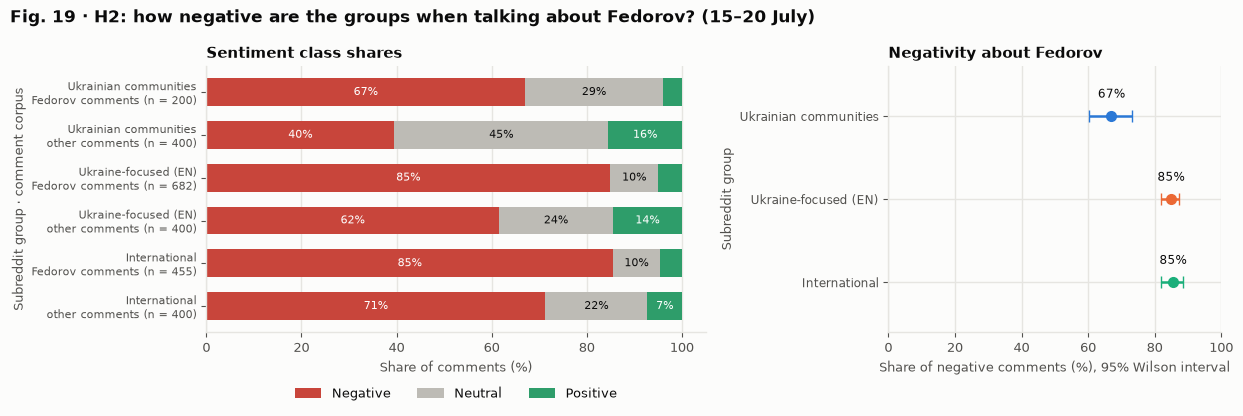

Negative share, Fedorov comments: {'Ukrainian communities': 67.0, 'Ukraine-focused (EN)': 84.9, 'International': 85.5}
Neutral share, Fedorov comments: {'Ukrainian communities': 29.0, 'Ukraine-focused (EN)': 10.1, 'International': 9.9}
H2 check (automatic): Ukrainian communities are significantly LESS negative than International (non-overlapping 95% CIs)  ->  H2 is not supported (the difference goes the opposite way). | International is NOT mostly neutral.


In [26]:
# Fig. 19 - H2: sentiment of Fedorov comments vs other comments, per subreddit group
def wilson(k, n, z=1.96):
    if n == 0: return (np.nan, np.nan)
    p = k / n; d = 1 + z * z / n; c = p + z * z / (2 * n); h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n))
    return ((c - h) / d, (c + h) / d)

if sent is None:
    print("Figure 19 needs the sentiment scores - see the previous cell.")
else:
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.3), gridspec_kw={"width_ratios": [1.5, 1]})
    cats = [(g, k_) for g in GROUP_ORDER for k_ in ("Fedorov comments", "other comments")]
    cols = {"Negative": "#c8453b", "Neutral": "#bdbbb5", "Positive": "#2e9d6a"}
    left = np.zeros(len(cats)); ylab = []
    shares = []
    for i, (g_, k_) in enumerate(cats):
        d_ = sent[(sent["group"] == g_) & (sent["kind"] == k_)]; shares.append(d_["label"].value_counts(normalize=True).reindex(cols).fillna(0) * 100); ylab.append(f"{g_}\n{k_} (n = {len(d_):,})")
    shares = pd.DataFrame(shares, index=range(len(cats)))
    for lab in cols:
        axes[0].barh(range(len(cats)), shares[lab], left=left, color=cols[lab], label=lab, height=0.65)
        for i_, (l_, v_) in enumerate(zip(left, shares[lab])):
            if v_ > 7: axes[0].text(l_ + v_ / 2, i_, f"{v_:.0f}%", ha="center", va="center", fontsize=8, color="white" if lab != "Neutral" else INK)
        left += shares[lab].values
    axes[0].set_yticks(range(len(cats))); axes[0].set_yticklabels(ylab, fontsize=8); axes[0].invert_yaxis(); axes[0].set_xlabel("Share of comments (%)"); axes[0].set_ylabel("Subreddit group · comment corpus")
    axes[0].set_title("Sentiment class shares"); axes[0].legend(ncols=3, loc="upper center", bbox_to_anchor=(0.5, -0.16)); axes[0].grid(axis="y", visible=False)
    # right: share of negative comments with Wilson 95% CI, Fedorov comments only
    for i, g_ in enumerate(GROUP_ORDER):
        d_ = sent[(sent["group"] == g_) & (sent["kind"] == "Fedorov comments")]; k_n = int((d_["label"] == "Negative").sum()); lo, hi = wilson(k_n, len(d_))
        axes[1].errorbar(k_n / len(d_) * 100, i, xerr=[[k_n / len(d_) * 100 - lo * 100], [hi * 100 - k_n / len(d_) * 100]], fmt="o", color=SERIES[g_], capsize=4, ms=7)
        axes[1].text(k_n / len(d_) * 100, i - 0.22, f"{k_n / len(d_) * 100:.0f}%", ha="center", fontsize=8.5)
    axes[1].set_yticks(range(3)); axes[1].set_yticklabels(GROUP_ORDER, fontsize=8.5); axes[1].set_ylim(2.6, -0.6); axes[1].set_xlim(0, 100)
    axes[1].set_xlabel("Share of negative comments (%), 95% Wilson interval"); axes[1].set_title("Negativity about Fedorov"); axes[1].set_ylabel("Subreddit group")
    fig.suptitle("Fig. 19 · H2: how negative are the groups when talking about Fedorov? (15–20 July)", x=0.01, ha="left", fontsize=12, weight="bold")
    fig.tight_layout(); finish(fig, "fig19_sentiment")
    neg = sent[sent["kind"] == "Fedorov comments"].groupby("group")["label"].apply(lambda s: (s == "Negative").mean()).reindex(GROUP_ORDER)
    print("Negative share, Fedorov comments:", (neg * 100).round(1).to_dict())
    ci = {}
    for g_ in GROUP_ORDER:
        d_ = sent[(sent["group"] == g_) & (sent["kind"] == "Fedorov comments")]; ci[g_] = wilson(int((d_["label"] == "Negative").sum()), len(d_))
    ua, it = ci["Ukrainian communities"], ci["International"]
    neu = sent[sent["kind"] == "Fedorov comments"].groupby("group")["label"].apply(lambda s: (s == "Neutral").mean()).reindex(GROUP_ORDER)
    print("Neutral share, Fedorov comments:", (neu * 100).round(1).to_dict())
    print("H2 check (automatic):",
          "Ukrainian communities are significantly MORE negative than International (non-overlapping 95% CIs)  ->  H2 is supported." if ua[0] > it[1] else
          "Ukrainian communities are significantly LESS negative than International (non-overlapping 95% CIs)  ->  H2 is not supported (the difference goes the opposite way)." if ua[1] < it[0] else
          "No significant difference in negativity between Ukrainian communities and International (overlapping 95% CIs)  ->  H2 is not supported.",
          "| International is mostly neutral." if neu["International"] > 0.5 else "| International is NOT mostly neutral.")

H2 is **not supported, and the difference goes the opposite way**. Among Fedorov comments, 67% are negative in Ukrainian communities (95% Wilson interval about 60–73%), against 85% in both the English Ukraine-focused and the international subreddits; the Ukrainian interval does not overlap with the international one. International subreddits are also not neutral: only 10% of their Fedorov comments are neutral. Two cautions apply: the model reads Ukrainian zero-shot, and negative tone mostly reflects the news itself (a dismissal, an outcry) rather than a stance on Fedorov as a person.

### 4.7 Poster text quality (H4)

The last question is about the posters themselves. We compare `user` (n = 711) and `ocr` (n = 257) posters on four noise metrics, using the `unknown` posters as the reference vocabulary and bootstrap intervals for the differences.

,posters,OOV tokens (%),mixed-script words (% posters),unusual symbols (% posters),isolated letters (% posters)
source,,,,,
user,711,36.3,0.1,1.5,3.8
ocr,257,42.1,0.4,2.7,5.4
unknown,3291,22.2,0.4,2.6,4.3


,OCR − typed (pp),95% CI low,95% CI high,clearly above 0?
OOV tokens (%),5.81,1.65,9.96,True
mixed-script words (% posters),0.25,-0.28,1.42,False
unusual symbols (% posters),1.18,-0.80,3.68,False
isolated letters (% posters),1.65,-1.28,4.94,False


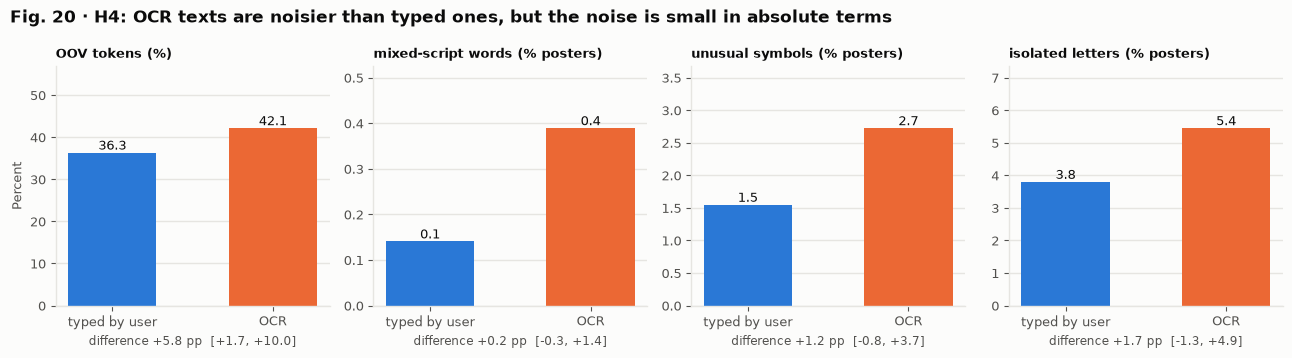

,text
2036,Арлії потрібні Реформи а не відкати
3042,ДРОНИ а не ТРУНИ
3983,"Досить помилятися, пане президенте!"
4365,"ДРАПАТИ + ФЕДОРОВ + 1 * = ПЕРЕМОГА НА ПРЕЗИДЕНТЕ, ТУТ МОЄ БУТИ ВАШЕ ІМ'Я. Я ВСЕ ЩЕ ВІР..."
3895,"ХОЧУ ЖИВИХ ЛЮДЕЙ, А НЕ СИРУ І М'ЯСА"
4279,"И пускай не раз Меня развели, Но ведь нету другого У меня страны"


In [27]:
# Fig. 20 - H4: are OCR-extracted poster texts noisier than typed ones?
kt = kart[kart["has_text"].astype(str).eq("True")].copy()
WORD = re.compile(r"[A-Za-zА-Яа-яІіЇїЄєҐґ'’ʼ]+"); LETTER_UA = re.compile(r"[а-яіїєґ'’ʼ]+")
LAT1, CYR1 = re.compile(r"[A-Za-z]"), re.compile(r"[А-Яа-яІіЇїЄєҐґ]")
ODD = re.compile(r"[^\w\s.,!?:;\-–—\"'«»“”„()…/%+#@№&*=\[\]|<>•’ʼ°$€₴^~_]", re.U)
vocab = Counter(w for t in kt.loc[kt["text_source"] == "unknown", "text"] for w in LETTER_UA.findall(t.lower()) if len(w) >= 3)
vocab = {w for w, c in vocab.items() if c >= 2}                       # reference vocabulary from the 'unknown' posters (never used in the comparison)
def metrics(t):
    ws = [w for w in LETTER_UA.findall(t.lower()) if len(w) >= 3]
    mixed = any(LAT1.search(w) and CYR1.search(w) for w in WORD.findall(t))
    frag = any(len(w) == 1 and w.lower() not in "иуавоясізйєю" for w in WORD.findall(t))
    return pd.Series({"oov": sum(w not in vocab for w in ws), "n_words": len(ws), "mixed": mixed, "odd": bool(ODD.search(t)), "frag": frag})
M = pd.concat([kt[["text_source"]], kt["text"].apply(metrics)], axis=1)
rows = []
for src_, d_ in M.groupby("text_source"):
    rows.append({"source": src_, "posters": len(d_), "OOV tokens (%)": d_["oov"].sum() / d_["n_words"].sum() * 100,
                 "mixed-script words (% posters)": d_["mixed"].mean() * 100, "unusual symbols (% posters)": d_["odd"].mean() * 100,
                 "isolated letters (% posters)": d_["frag"].mean() * 100})
R = pd.DataFrame(rows).set_index("source").loc[["user", "ocr", "unknown"]]
display(R.round(1))
# bootstrap (resampling posters) for the OCR - typed difference; 'unknown' is excluded from the plot because the reference vocabulary was built from it
Mu, Mo = M[M["text_source"] == "user"].reset_index(drop=True), M[M["text_source"] == "ocr"].reset_index(drop=True)
def stat(d_):
    return np.array([d_["oov"].sum() / d_["n_words"].sum() * 100, d_["mixed"].mean() * 100, d_["odd"].mean() * 100, d_["frag"].mean() * 100])
rng2 = np.random.default_rng(5); boots = []
for _ in range(1000):
    boots.append(stat(Mo.iloc[rng2.integers(0, len(Mo), len(Mo))]) - stat(Mu.iloc[rng2.integers(0, len(Mu), len(Mu))]))
boots = np.array(boots); diff = stat(Mo) - stat(Mu)
lo_, hi_ = np.percentile(boots, 2.5, axis=0), np.percentile(boots, 97.5, axis=0)
mnames = list(R.columns[1:])
display(pd.DataFrame({"OCR − typed (pp)": diff.round(2), "95% CI low": lo_.round(2), "95% CI high": hi_.round(2),
                      "clearly above 0?": lo_ > 0}, index=mnames))

fig, axes = plt.subplots(1, 4, figsize=(13, 3.6))
for ax, m_, k_ in zip(axes, mnames, range(4)):
    v = R.loc[["user", "ocr"], m_]
    ax.bar(["typed by user", "OCR"], v.values, color=["#2a78d6", "#eb6834"], width=0.55)
    for i, vv in enumerate(v.values): ax.text(i, vv, f"{vv:.1f}", ha="center", va="bottom", fontsize=9)
    ax.set_title(m_, fontsize=9.5); ax.set_ylim(0, v.max() * 1.35); ax.grid(axis="x", visible=False)
    ax.set_xlabel(f"difference {diff[k_]:+.1f} pp  [{lo_[k_]:+.1f}, {hi_[k_]:+.1f}]", fontsize=8.5)
axes[0].set_ylabel("Percent")
fig.suptitle("Fig. 20 · H4: OCR texts are noisier than typed ones, but the noise is small in absolute terms", x=0.01, ha="left", fontsize=12, weight="bold")
fig.tight_layout(); finish(fig, "fig20_ocr_quality")
display(kt[kt["text_source"] == "ocr"][["text"]].sample(6, random_state=3))

H4 is **weakly supported**: OCR texts contain 5.8 percentage points more out-of-vocabulary tokens (95% CI [1.7, 10.0]), while the other differences cannot be told apart from zero. There is no evidence of systematic character errors that would call for correction.

## 5. Evaluation

### 5.1 Answers to the research questions

The data answer the opening questions in the order they were asked. The three international subreddits hold 84% of all comments and the Ukrainian communities only about 6% (Q1, Fig. 1); removed or deleted comments amount to 4.4% in Ukrainian communities, 4.3% in Ukraine-focused ones and 13.1% in international ones, with bots at 0.6–5.2% (Q2, Fig. 2). The offline data cover 4,448 posters, but 78% have an unknown text source and 79% of dates are upload times; Kyiv leads with 39% (Q3, Fig. 3).

The protest does not change overall Reddit traffic, whose volume stays stable (Q4, Fig. 4). Ukrainian communities comment from 9:00 to midnight with a peak at 21:00, international ones peak around 17:00 Kyiv time (Q5, Fig. 5). Participation is concentrated: the top 1% of authors write 24% of comments, and 47% of authors write only once (Q6, Fig. 6). Most comments score 1–3 and have a median length of 10–19 words (Q7, Figs. 7–8). Popularity predicts discussion size well in the English groups (Spearman ρ ≈ 0.76) and poorly in Ukrainian communities (0.35) (Q8, Fig. 9). Submissions and comments can be joined, and 99.0% of comments find their submission (Q9, Fig. 10).

Reddit peaks on 16 July, with a surge from 21:00 on 15 July, while dated posters peak on 18 July (Q10, Figs. 11–12). The English Ukraine-focused subreddits react most strongly (432 mentions per 10,000 comments) and the international ones least (40); the authors are established users and the threads are news threads (Q11, Figs. 13–15). Posters and comments share names and roles rather than slogans (Q12, Figs. 16–18). Fedorov comments are negative in 67% of cases in Ukrainian communities and in 85% in English-language and international subreddits, so the Ukrainian side is the milder one (Q13, Fig. 19), while OCR texts show modestly more out-of-vocabulary tokens but no clear systematic errors (Q14, Fig. 20).

### 5.2 Hypotheses

Looking back at the four hypotheses, **H1** (keyword convergence) is partly supported, in its weak form only. **H2** (sentiment divergence) is not supported: the Ukrainian communities are less negative than the international subreddits (67% vs 85%), not more. **H3** (news-driven spikes) is postponed, with leads in Figs. 11, 15 and 16. **H4** (OCR noise) is weakly supported.

### 5.3 Limitations

Every story has its blind spots. On the poster side, 78% of texts have an unknown source, only about 21% of dates are reliable and cities are self-reported. On the Reddit side, scores and `num_comments` are early snapshots, and Fedorov is matched by a regular expression, so comments about the event that never use the name are missed. Ukrainian posters set against mostly English comments limit H1, and Ukrainian sentiment is a zero-shot transfer, so the H2 result should be read with care. Finally, we use two months of data rather than six, which is justified by the local, event-centred topic.

## 6. Conclusions and future work

### 6.1 Conclusions

The protest changed the topic of conversation, not its volume. Total Reddit traffic stayed flat, yet comments mentioning Fedorov rose from 129 to 614 in a single day. The reaction came from the screen before the street: Reddit peaked on 16 July, two days before the dated posters peaked on 18 July. It was also very uneven between communities, with 432, 228 and 40 mentions per 10,000 comments in English Ukraine-focused, Ukrainian and international subreddits respectively, and it was driven by users who were already active rather than by newcomers.

The texts tell a similar story of two registers. Posters chant and comments analyse, so lexical convergence (H1) holds only weakly, while OCR noise (H4) turns out to be modest. Underneath, the two Reddit sources combine well — 99% of comments find their thread — and participation is highly concentrated, since the top 1% of authors write 24% of all comments. The one hypothesis that failed outright is H2: instead of Ukrainian communities being the angriest, 85% of the English-language and international Fedorov comments are negative against 67% in Ukrainian communities.

### 6.2 Future work

The next chapter is the news layer needed for H3: a dated event list and GDELT daily coverage for 1 July – 31 August, aligned with the Fedorov series and tested for lead and lag. The same news can then be set beside poster keywords, Reddit keywords and headlines for the day before the protests, 16 July and the days after. Two methodological steps would make the story more trustworthy: validating sentiment on a hand-labelled sample with separate models for Ukrainian and English, and sending a sample of OCR corrections to the author of the archive.